### 1. Import Library

In [12]:
import os
import warnings

warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import seaborn as sns

import google.auth
from pathlib import Path
from google.cloud import bigquery

### 2. Setup and Configuration

In [2]:

# SECTION 1: SETUP & CONFIGURATION

plt.rcParams.update({
    "figure.figsize": (14, 6),
    "figure.facecolor": "white",
    "figure.dpi": 100,

    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlepad": 15,
    "axes.labelsize": 11,
    "axes.labelweight": "bold",

    "axes.facecolor": "#F8F9FA",
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": "#E0E0E0",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    "xtick.labelsize": 10,
    "ytick.labelsize": 10,

    "legend.fontsize": 10,
    "legend.framealpha": 0.9,

    "savefig.bbox": "tight",
    "savefig.dpi": 150,
})

COLORS = {
    "primary": "#2196F3",    # Blue: main metric
    "secondary": "#FF9800",  # Orange: comparison
    "success": "#4CAF50",    # Green: positive
    "danger": "#F44336",     # Red: negative / alert
    "neutral": "#9E9E9E",    # Gray: reference
    "purple": "#9C27B0",     # Purple: accent
    "teal": "#009688",       # Teal: secondary metric
}

PALETTE_5 = [
    "#2196F3",
    "#4CAF50",
    "#FF9800",
    "#F44336",
    "#9C27B0",
]

PROJECT_ID = "olist-ecommerce-analytics-1"

MART_DATASET = f"{PROJECT_ID}.olist_mart"
REPORTING_DATASET = f"{PROJECT_ID}.olist_reporting"

def get_bq_client(project_id: str) -> bigquery.Client:

    credentials, _ = google.auth.default(
        scopes=["https://www.googleapis.com/auth/cloud-platform"]
    )

    return bigquery.Client(
        project=project_id,
        credentials=credentials,
    )

def run_query(
    client: bigquery.Client,
    query: str,
) -> pd.DataFrame:

    query_job = client.query(query)

    return query_job.result().to_dataframe()

client = get_bq_client(PROJECT_ID)

print("BigQuery client initialized successfully")


BigQuery client initialized successfully


### 3. Load Data

In [3]:
query_orders = f"""
    SELECT
        order_id,
        customer_unique_id,
        order_status,
        purchase_date,
        purchase_year,
        purchase_month,
        purchase_year_month,
        purchase_year_quarter,
        purchase_day_of_week,
        is_revenue_generating,
        is_delivered,
        is_ontime_delivery,
        is_order_date_anomaly,
        purchase_to_delivery_days,
        delivery_vs_estimated_days,
        total_price,
        total_freight_value,
        total_gmv,
        item_count,
        primary_payment_type,
        max_installments,
        used_voucher,
        review_score,
        review_sentiment,
        customer_type,
        rfm_segment,
        clv_tier
    FROM `{MART_DATASET}.fact_orders`
"""
df_orders = run_query(client, query_orders)
df_orders['purchase_date'] = pd.to_datetime(df_orders['purchase_date'])
print(f"fact_orders loaded: {len(df_orders):>8,} rows")

df_delivered = df_orders[
    df_orders['is_revenue_generating'] == True
].copy()

fact_orders loaded:   98,666 rows


In [4]:
numeric_columns = [
    "total_price",
    "total_freight_value",
    "total_gmv",
]

for col in numeric_columns:
    df_delivered[col] = pd.to_numeric(
        df_delivered[col],
        errors="raise"
    )

df_delivered["purchase_date"] = pd.to_datetime(
    df_delivered["purchase_date"],
    errors="raise"
)

integer_columns = [
    "purchase_year",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_to_delivery_days",
    "delivery_vs_estimated_days",
    "item_count",
    "max_installments",
    "review_score",
]

for col in integer_columns:
    df_delivered[col] = df_delivered[col].astype("Int64")

boolean_columns = [
    "is_revenue_generating",
    "is_delivered",
    "is_ontime_delivery",
    "is_order_date_anomaly",
    "used_voucher",
]

for col in boolean_columns:
    df_delivered[col] = df_delivered[col].astype("boolean")

print(df_delivered.dtypes)

df_delivered.info()


order_id                                str
customer_unique_id                      str
order_status                            str
purchase_date                 datetime64[s]
purchase_year                         Int64
purchase_month                        Int64
purchase_year_month                     str
purchase_year_quarter                   str
purchase_day_of_week                  Int64
is_revenue_generating               boolean
is_delivered                        boolean
is_ontime_delivery                  boolean
is_order_date_anomaly               boolean
purchase_to_delivery_days             Int64
delivery_vs_estimated_days            Int64
total_price                         float64
total_freight_value                 float64
total_gmv                           float64
item_count                            Int64
primary_payment_type                    str
max_installments                      Int64
used_voucher                        boolean
review_score                    

### 4. Distribusi Order Value

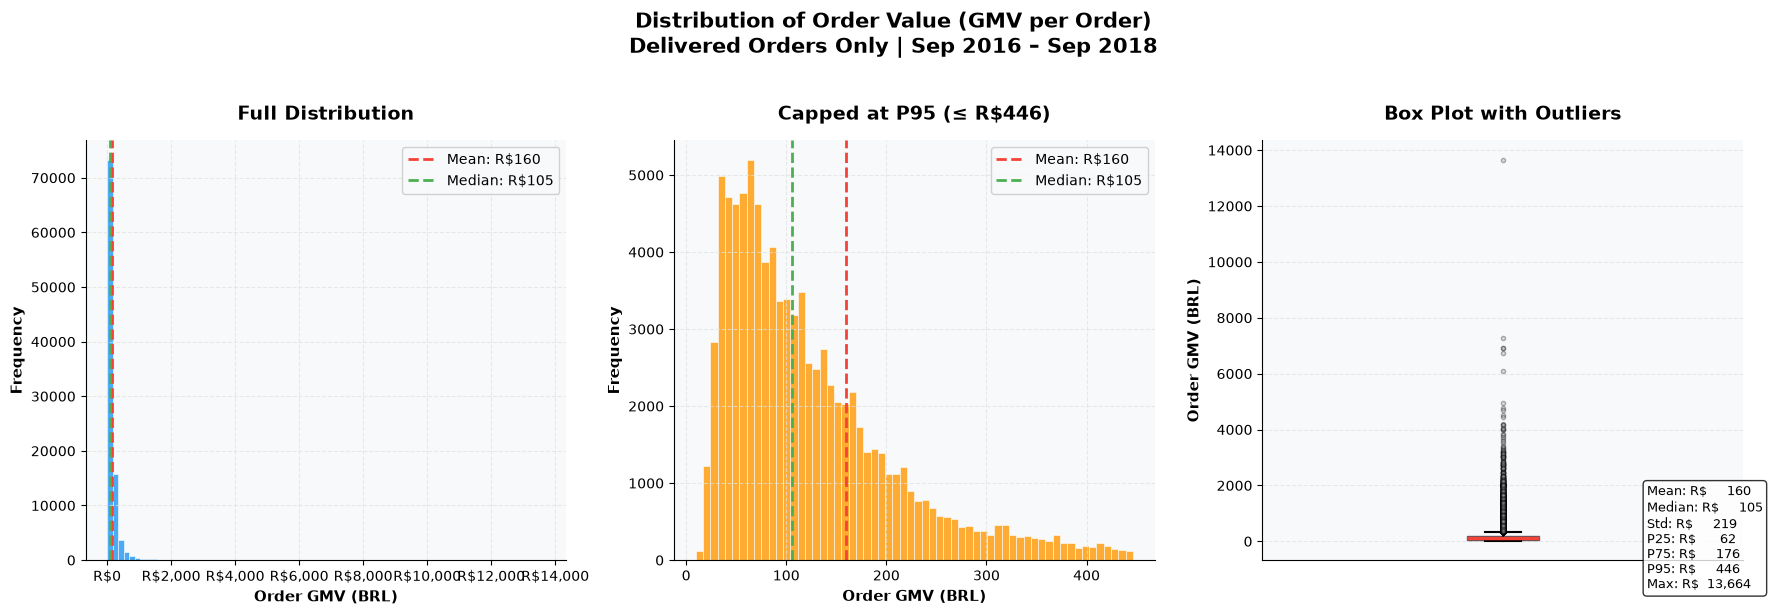


 ORDER VALUE STATISTICS:
 Count: 96,478
 Mean: R$159.83
 Median: R$105.28
 Std Dev: R$218.79
 Skewness: 9.368 (Right-skewed)
 P90: R$305.92
 P95: R$446.23
 P99: R$1,052.39

 Mean (R$160) > Median (R$105)


In [5]:
# 2.1 DISTRIBUSI ORDER VALUE (GMV per Order)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    'Distribution of Order Value (GMV per Order)\n'
    'Delivered Orders Only | Sep 2016 – Sep 2018',
    fontsize=15, fontweight='bold', y=1.02
)

gmv_data = df_delivered['total_gmv'].dropna()

# Plot 1: Histogram (full range)
ax1 = axes[0]
ax1.hist(
    gmv_data,
    bins=80,
    color=COLORS['primary'],
    alpha=0.8,
    edgecolor='white',
    linewidth=0.5
)
ax1.set_xlabel('Order GMV (BRL)')
ax1.set_ylabel('Frequency')
ax1.set_title('Full Distribution')
ax1.axvline(
    gmv_data.mean(),
    color=COLORS['danger'],
    linestyle='--',
    linewidth=2,
    label=f"Mean: R${gmv_data.mean():.0f}"
)
ax1.axvline(
    gmv_data.median(),
    color=COLORS['success'],
    linestyle='--',
    linewidth=2,
    label=f"Median: R${gmv_data.median():.0f}"
)
ax1.legend()
ax1.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'R${x:,.0f}')
)

# Plot 2: Histogram (capped at P95 untuk visibility)
ax2 = axes[1]
p95 = gmv_data.quantile(0.95)
gmv_trimmed = gmv_data[gmv_data <= p95]
ax2.hist(
    gmv_trimmed,
    bins=60,
    color=COLORS['secondary'],
    alpha=0.8,
    edgecolor='white',
    linewidth=0.5
)
ax2.set_xlabel('Order GMV (BRL)')
ax2.set_ylabel('Frequency')
ax2.set_title(f'Capped at P95 (≤ R${p95:,.0f})')
ax2.axvline(
    gmv_data.mean(),
    color=COLORS['danger'],
    linestyle='--',
    linewidth=2,
    label=f"Mean: R${gmv_data.mean():.0f}"
)
ax2.axvline(
    gmv_data.median(),
    color=COLORS['success'],
    linestyle='--',
    linewidth=2,
    label=f"Median: R${gmv_data.median():.0f}"
)
ax2.legend()

# Plot 3: Box Plot dengan outlier detail
ax3 = axes[2]
bp = ax3.boxplot(
    gmv_data,
    vert=True,
    patch_artist=True,
    boxprops=dict(facecolor=COLORS['primary'], alpha=0.6),
    medianprops=dict(color=COLORS['danger'], linewidth=2.5),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
    flierprops=dict(
        marker='o', markersize=3,
        markerfacecolor=COLORS['neutral'], alpha=0.3
    )
)
ax3.set_ylabel('Order GMV (BRL)')
ax3.set_title('Box Plot with Outliers')

stats_text = (
    f"Mean: R${gmv_data.mean():>8,.0f}\n"
    f"Median: R${gmv_data.median():>8,.0f}\n"
    f"Std: R${gmv_data.std():>8,.0f}\n"
    f"P25: R${gmv_data.quantile(.25):>8,.0f}\n"
    f"P75: R${gmv_data.quantile(.75):>8,.0f}\n"
    f"P95: R${gmv_data.quantile(.95):>8,.0f}\n"
    f"Max: R${gmv_data.max():>8,.0f}"
)
ax3.text(
    1.3, gmv_data.median(),
    stats_text,
    fontsize=9,
    verticalalignment='center',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
)
ax3.set_xticks([])

plt.tight_layout()
plt.savefig('../assets/eda/01_order_value_distribution.png')
plt.show()

skewness = gmv_data.skew()
print(f"\n ORDER VALUE STATISTICS:")
print(f" Count: {len(gmv_data):,}")
print(f" Mean: R${gmv_data.mean():,.2f}")
print(f" Median: R${gmv_data.median():,.2f}")
print(f" Std Dev: R${gmv_data.std():,.2f}")
print(f" Skewness: {skewness:.3f} "
      f"({'Right-skewed' if skewness > 0 else 'Left-skewed'})")
print(f" P90: R${gmv_data.quantile(.90):,.2f}")
print(f" P95: R${gmv_data.quantile(.95):,.2f}")
print(f" P99: R${gmv_data.quantile(.99):,.2f}")
print(f"\n Mean (R${gmv_data.mean():.0f}) > Median (R${gmv_data.median():.0f})")

Analisis distribusi GMV memiliki nilai R$96,478 total order yang berstatus delivered pada periode September 2016 - September 2018. Hasil distribusi menunjukkan bahwa distribusi berbentuk right skewed dengan nilai 9.368.

Rata rata GMV per pesanan memiliki nilai R$159.83 sementara median memiliki nilai R$105.28. Sementara itu, persentil ke-95 mencapai R$446,23 dan persentil ke-99 mencapai R$1.052,39, dengan nilai maksimum sebesar R$13.664.

Histogram dan box plot menunjukkan adanya ekor distribusi yang panjang serta beberapa outlier yang bernilia tinggi. Kondisi ini menunjukkan bahwa rata rata tidak bisa merepresentasikan nilai transaksi yang tipikal. Oleh karena itu median dan persentil digunakan sebagai metrik pendamping.

Analisis lanjutan perlu mengidentifikasi kategori produk, jumlah item per pesanan, dan karakteristik pelanggan yang berkaitan dengan transaksi bernilai tinggi.

### 5. Distribusi Review Score

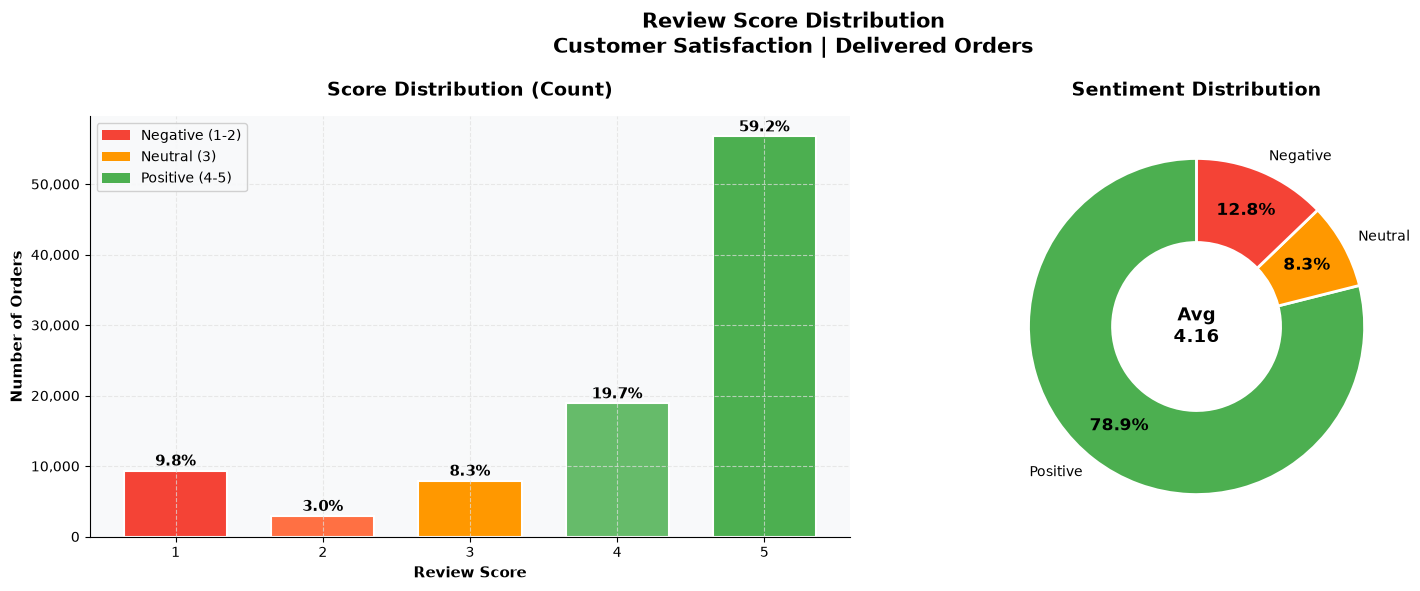


 REVIEW SCORE STATISTICS:
 Avg review score: 4.156
 Median: 5.0
 Review response rate: 99.3%


In [6]:
# 2.2 DISTRIBUSI REVIEW SCORE

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(
    'Review Score Distribution\n'
    'Customer Satisfaction | Delivered Orders',
    fontsize=15, fontweight='bold'
)

review_counts = df_delivered['review_score'].value_counts().sort_index()
review_pct    = review_counts / review_counts.sum() * 100

bar_colors = {
    1: COLORS['danger'],
    2: '#FF7043',
    3: COLORS['secondary'],
    4: '#66BB6A',
    5: COLORS['success']
}

# Plot 1: Bar chart distribusi
ax1 = axes[0]
bars = ax1.bar(
    review_counts.index,
    review_counts.values,
    color=[bar_colors[s] for s in review_counts.index],
    edgecolor='white',
    linewidth=1.5,
    width=0.7
)

for bar, pct in zip(bars, review_pct):
    ax1.text(
        bar.get_x() + bar.get_width() / 2.,
        bar.get_height() + 200,
        f'{pct:.1f}%',
        ha='center', va='bottom',
        fontsize=11, fontweight='bold'
    )

ax1.set_xlabel('Review Score')
ax1.set_ylabel('Number of Orders')
ax1.set_title('Score Distribution (Count)')
ax1.set_xticks([1, 2, 3, 4, 5])
ax1.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x:,.0f}')
)

legend_elements = [
    mpatches.Patch(facecolor=COLORS['danger'], label='Negative (1-2)'),
    mpatches.Patch(facecolor=COLORS['secondary'], label='Neutral (3)'),
    mpatches.Patch(facecolor=COLORS['success'], label='Positive (4-5)')
]
ax1.legend(handles=legend_elements, loc='upper left')

# Plot 2: Sentiment summary donut chart
ax2 = axes[1]
sentiment_counts = df_delivered['review_sentiment'].value_counts()
sentiment_colors = {
    'Positive': COLORS['success'],
    'Neutral':  COLORS['secondary'],
    'Negative': COLORS['danger']
}

# Reorder: Positive, Neutral, Negative
ordered_sentiments = ['Positive', 'Neutral', 'Negative']
sizes  = [sentiment_counts.get(s, 0) for s in ordered_sentiments]
colors = [sentiment_colors[s] for s in ordered_sentiments]

wedges, texts, autotexts = ax2.pie(
    sizes,
    labels=ordered_sentiments,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.75,
    wedgeprops=dict(width=0.5, edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_fontweight('bold')

avg_score = df_delivered['review_score'].mean()
ax2.text(
    0, 0,
    f"Avg\n{avg_score:.2f}",
    ha='center', va='center',
    fontsize=13, fontweight='bold'
)
ax2.set_title('Sentiment Distribution')

plt.tight_layout()
plt.savefig('../assets/eda/02_review_score_distribution.png')
plt.show()

null_reviews = df_delivered['review_score'].isna().sum()
review_rate  = (1 - null_reviews / len(df_delivered)) * 100

print(f"\n REVIEW SCORE STATISTICS:")
print(f" Avg review score: {avg_score:.3f}")
print(f" Median: {df_delivered['review_score'].median():.1f}")
print(f" Review response rate: {review_rate:.1f}%")

Berdasarkan data yang dimiliki, rata rata review score yaitu 4.156 dari dan sebanyak 78.9% ulasan berada pada kategori positif (rating 4-5). Rating 5 mendominasi sebesar 59.2% menunjukkan mayoritas pelanggan memberikan penilaian yang sangat baik terhadap pengalaman pembelian mereka. Namun masih terdapat 12.8% review negatif dengan dominan rating 1 sebesar 9.8%. Hal ini wajib diinvestigasi guna meningkatkan tingkat kepuasan pelanggan

### 6. Distirbusi Delivery Duration

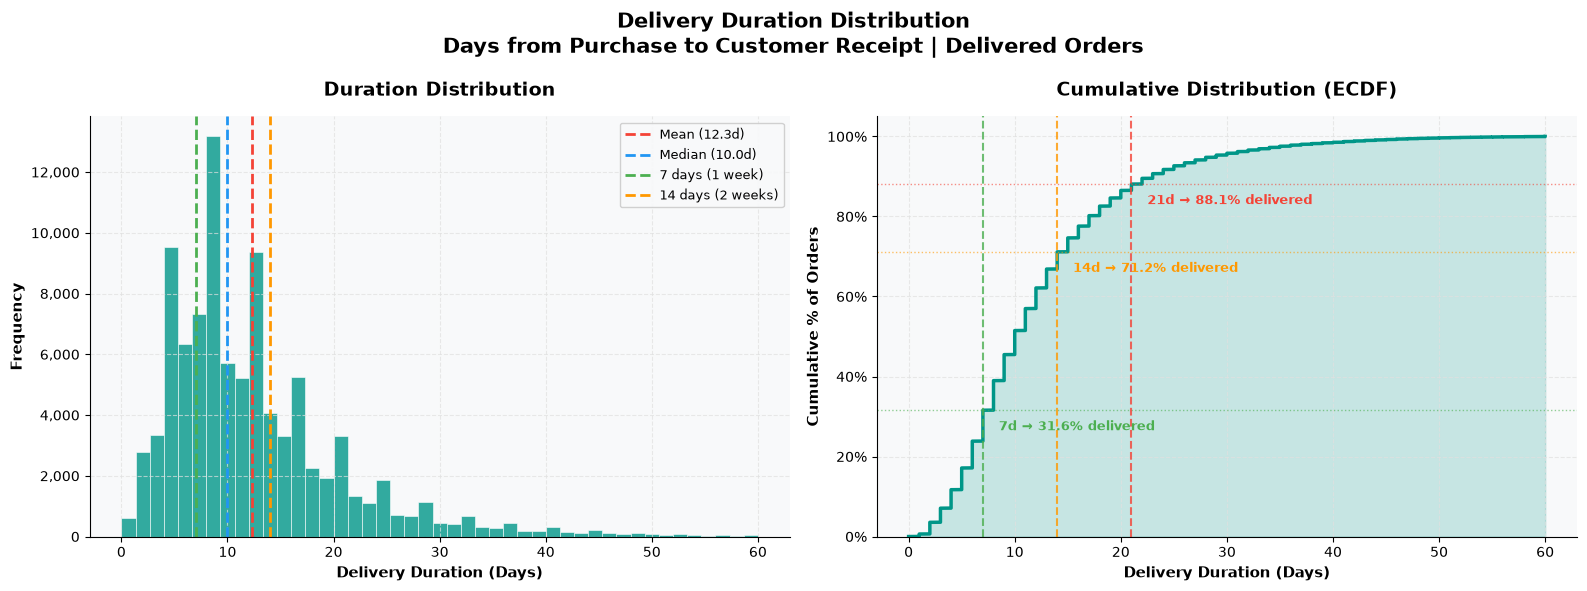


 DELIVERY DURATION STATISTICS:
Mean: 12.32 days
Median: 10.00 days
Std Dev: 8.41 days
Min: 0 days
Max: 60 days

   % delivered within:
≤ 7 days: 31.6%
≤ 14 days: 71.2%
≤ 21 days: 88.1%


In [7]:
# 2.3 DISTRIBUSI DELIVERY DURATION

delivery_data = df_delivered[
    (df_delivered['purchase_to_delivery_days'].notna()) &
    (df_delivered['is_order_date_anomaly'] == False) &
    (df_delivered['purchase_to_delivery_days'] >= 0) &
    (df_delivered['purchase_to_delivery_days'] <= 60)  # Cap outlier ekstrem
]['purchase_to_delivery_days']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(
    'Delivery Duration Distribution\n'
    'Days from Purchase to Customer Receipt | Delivered Orders',
    fontsize=15, fontweight='bold'
)

# Plot 1: Histogram dengan estimated delivery target
ax1 = axes[0]
ax1.hist(
    delivery_data,
    bins=45,
    color=COLORS['teal'],
    alpha=0.8,
    edgecolor='white',
    linewidth=0.5
)

for val, label, color in [
    (delivery_data.mean(),   f'Mean ({delivery_data.mean():.1f}d)',   COLORS['danger']),
    (delivery_data.median(), f'Median ({delivery_data.median():.1f}d)', COLORS['primary']),
    (7,  '7 days (1 week)', COLORS['success']),
    (14, '14 days (2 weeks)', COLORS['secondary']),
]:
    ax1.axvline(val, color=color, linestyle='--', linewidth=2, label=label)

ax1.set_xlabel('Delivery Duration (Days)')
ax1.set_ylabel('Frequency')
ax1.set_title('Duration Distribution')
ax1.legend(fontsize=9)
ax1.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x:,.0f}')
)

# Plot 2: Cumulative distribution (ECDF)
ax2 = axes[1]
sorted_data  = np.sort(delivery_data)
cdf          = np.arange(1, len(sorted_data) + 1) / len(sorted_data)

ax2.plot(sorted_data, cdf * 100, color=COLORS['teal'], linewidth=2.5)
ax2.fill_between(sorted_data, cdf * 100, alpha=0.2, color=COLORS['teal'])

for days, color, ls in [(7, COLORS['success'], '-'), (14, COLORS['secondary'], '-'), (21, COLORS['danger'], '-')]:
    pct = (delivery_data <= days).mean() * 100
    ax2.axvline(days, color=color, linestyle='--', linewidth=1.5, alpha=0.8)
    ax2.axhline(pct, color=color, linestyle=':', linewidth=1, alpha=0.6)
    ax2.annotate(
        f'{days}d → {pct:.1f}% delivered',
        xy=(days, pct),
        xytext=(days + 1.5, pct - 5),
        fontsize=9,
        color=color,
        fontweight='bold'
    )

ax2.set_xlabel('Delivery Duration (Days)')
ax2.set_ylabel('Cumulative % of Orders')
ax2.set_title('Cumulative Distribution (ECDF)')
ax2.set_ylim(0, 105)
ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x:.0f}%')
)

plt.tight_layout()
plt.savefig('../assets/eda/03_delivery_duration_distribution.png')
plt.show()

pct_7d  = (delivery_data <= 7).mean() * 100
pct_14d = (delivery_data <= 14).mean() * 100
pct_21d = (delivery_data <= 21).mean() * 100

print(f"\n DELIVERY DURATION STATISTICS:")
print(f"Mean: {delivery_data.mean():.2f} days")
print(f"Median: {delivery_data.median():.2f} days")
print(f"Std Dev: {delivery_data.std():.2f} days")
print(f"Min: {delivery_data.min():.0f} days")
print(f"Max: {delivery_data.max():.0f} days")
print(f"\n   % delivered within:")
print(f"≤ 7 days: {pct_7d:.1f}%")
print(f"≤ 14 days: {pct_14d:.1f}%")
print(f"≤ 21 days: {pct_21d:.1f}%")

Mayoritas pesanan diterima dalam waktu 1 -2 minggu, dengan median durasi 10 hari dan rata rata 12.3 hari. Sebanyak 71.2% pesanan diterima dalam waktu maksimal 14 hari, sementara 28.8% memakan waktu lebih lama. Distribusi yang miring ke kanan menunjukkan adanya sejumlah pesanan dengan durasi pengiriman ekstrem hingga sekitar 60 hari.

Prioritaskan evaluasi pengiriman dengan durasi lebih dari 14 hari, terutama kelompok yang membutuhkan waktu lebih dari 21 hari. Butuh analisis lanjutan berdasarkan wilayah, seller, dan penyedia logistik serta hubungan durasi pengiriman dengan review score untuk mengidentifikasi peluang peningkatan efisiensi dan kepuasan pelanggan.

### 7. Review Score vs Delivery Time

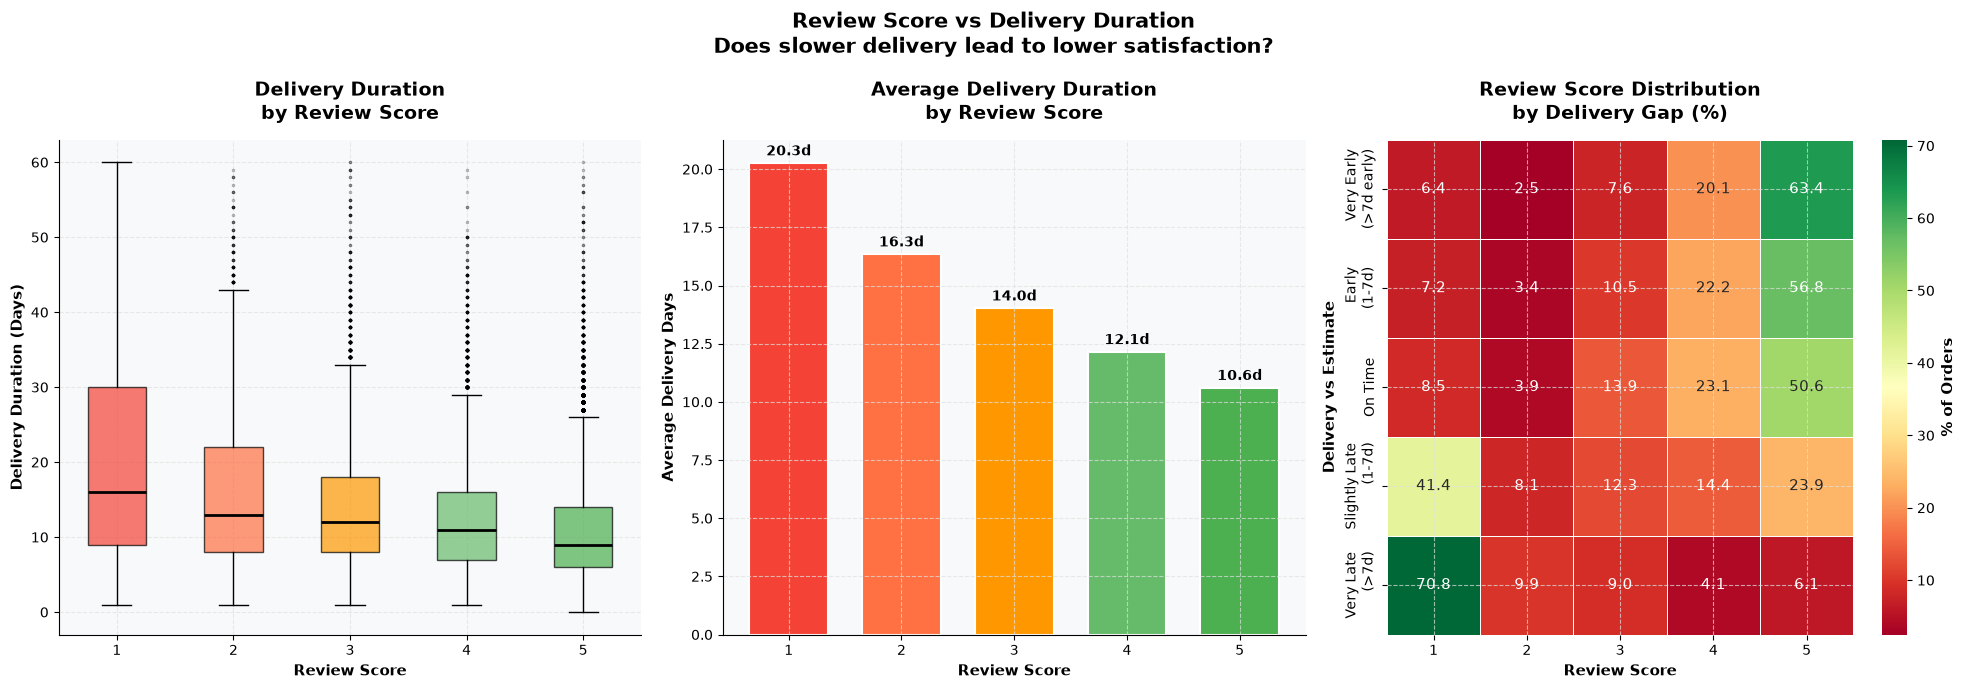


 REVIEW SCORE vs DELIVERY TIME CORRELATION:
 Pearson r: -0.3447
 Spearman rho: -0.2316

 Average delivery days by review score:
   Score 1:  20.3 days (9,078 orders)
   Score 2:  16.3 days (2,868 orders)
   Score 3:  14.0 days (7,811 orders)
   Score 4:  12.1 days (18,589 orders)
   Score 5:  10.6 days (55,831 orders)


In [8]:
# 3.1 REVIEW SCORE vs DELIVERY TIME
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
fig.suptitle(
    'Review Score vs Delivery Duration\n'
    'Does slower delivery lead to lower satisfaction?',
    fontsize=15, fontweight='bold'
)

bivar_df = df_delivered[
    df_delivered['review_score'].notna() &
    df_delivered['purchase_to_delivery_days'].notna() &
    (df_delivered['is_order_date_anomaly'] == False) &
    (df_delivered['purchase_to_delivery_days'] <= 60)
].copy()

score_colors = {1: '#F44336', 2: '#FF7043', 3: '#FF9800',
                4: '#66BB6A', 5: '#4CAF50'}

# Plot 1: Box plot — delivery days per review score
ax1 = axes[0]
review_groups = [
    bivar_df[bivar_df['review_score'] == score]['purchase_to_delivery_days'].dropna()
    for score in [1, 2, 3, 4, 5]
]

bp = ax1.boxplot(
    review_groups,
    label=['Score 1', 'Score 2', 'Score 3', 'Score 4', 'Score 5'],
    patch_artist=True,
    medianprops=dict(color='black', linewidth=2),
    flierprops=dict(marker='.', markersize=3, alpha=0.3)
)
for patch, color in zip(bp['boxes'], score_colors.values()):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax1.set_xlabel('Review Score')
ax1.set_ylabel('Delivery Duration (Days)')
ax1.set_title('Delivery Duration\nby Review Score')

# Plot 2: Bar chart — mean delivery days per score
ax2 = axes[1]
mean_delivery_by_score = bivar_df.groupby('review_score')[
    'purchase_to_delivery_days'
].agg(['mean', 'count']).reset_index()

bars = ax2.bar(
    mean_delivery_by_score['review_score'],
    mean_delivery_by_score['mean'],
    color=[score_colors[s] for s in mean_delivery_by_score['review_score']],
    edgecolor='white',
    linewidth=1.5,
    width=0.7
)
for bar, (_, row) in zip(bars, mean_delivery_by_score.iterrows()):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f'{row["mean"]:.1f}d',
        ha='center', va='bottom',
        fontsize=10, fontweight='bold'
    )

ax2.set_xlabel('Review Score')
ax2.set_ylabel('Average Delivery Days')
ax2.set_title('Average Delivery Duration\nby Review Score')
ax2.set_xticks([1, 2, 3, 4, 5])

# Plot 3: Heatmap delivery gap vs review score
ax3 = axes[2]
gap_score_df = bivar_df[
    bivar_df['delivery_vs_estimated_days'].notna()
].copy()
gap_score_df['gap_bucket'] = pd.cut(
    gap_score_df['delivery_vs_estimated_days'],
    bins=[-30, -7, -1, 0, 7, 100],
    labels=['Very Early\n(>7d early)', 'Early\n(1-7d)', 'On Time', 'Slightly Late\n(1-7d)', 'Very Late\n(>7d)']
)

heatmap_data = gap_score_df.groupby(
    ['gap_bucket', 'review_score']
).size().unstack(fill_value=0)

# Normalize per row (% dalam setiap gap bucket)
heatmap_pct = heatmap_data.div(heatmap_data.sum(axis=1), axis=0) * 100

sns.heatmap(
    heatmap_pct,
    ax=ax3,
    cmap='RdYlGn',
    annot=True,
    fmt='.1f',
    cbar_kws={'label': '% of Orders'},
    linewidths=0.5
)
ax3.set_xlabel('Review Score')
ax3.set_ylabel('Delivery vs Estimate')
ax3.set_title('Review Score Distribution\nby Delivery Gap (%)')

plt.tight_layout()
plt.savefig('../assets/eda/04_review_vs_delivery.png')
plt.show()

# Correlation
corr = bivar_df[['review_score', 'purchase_to_delivery_days']].corr()
spearman_corr = bivar_df[['review_score', 'purchase_to_delivery_days']].corr(method='spearman')

print(f"\n REVIEW SCORE vs DELIVERY TIME CORRELATION:")
print(f" Pearson r: {corr.iloc[0,1]:.4f}")
print(f" Spearman rho: {spearman_corr.iloc[0,1]:.4f}")
print(f"\n Average delivery days by review score:")
for _, row in mean_delivery_by_score.iterrows():
    print(f"   Score {int(row['review_score'])}: {row['mean']:5.1f} days "
          f"({row['count']:,} orders)")

Terdapat hubungan negatif antara durasi pengiriman dan kepuasan pelanggan. Pesanan dengan rating 1 memiliki rata-rata durasi pengiriman 20,3 hari, sedangkan pesanan dengan rating 5 hanya 10,6 hari. Selain itu, 80,7% pesanan yang terlambat lebih dari 7 hari memperoleh rating negatif, sementara 83,5% pesanan yang diterima lebih dari 7 hari sebelum estimasi memperoleh rating positif.

Prioritaskan peningkatan ketepatan waktu pengiriman, terutama dengan mengurangi keterlambatan lebih dari 7 hari. Optimalkan estimasi waktu pengiriman dan evaluasi performa logistik berdasarkan wilayah serta seller untuk meningkatkan kepuasan pelanggan.

### 8. Order Value vs Payment Installments

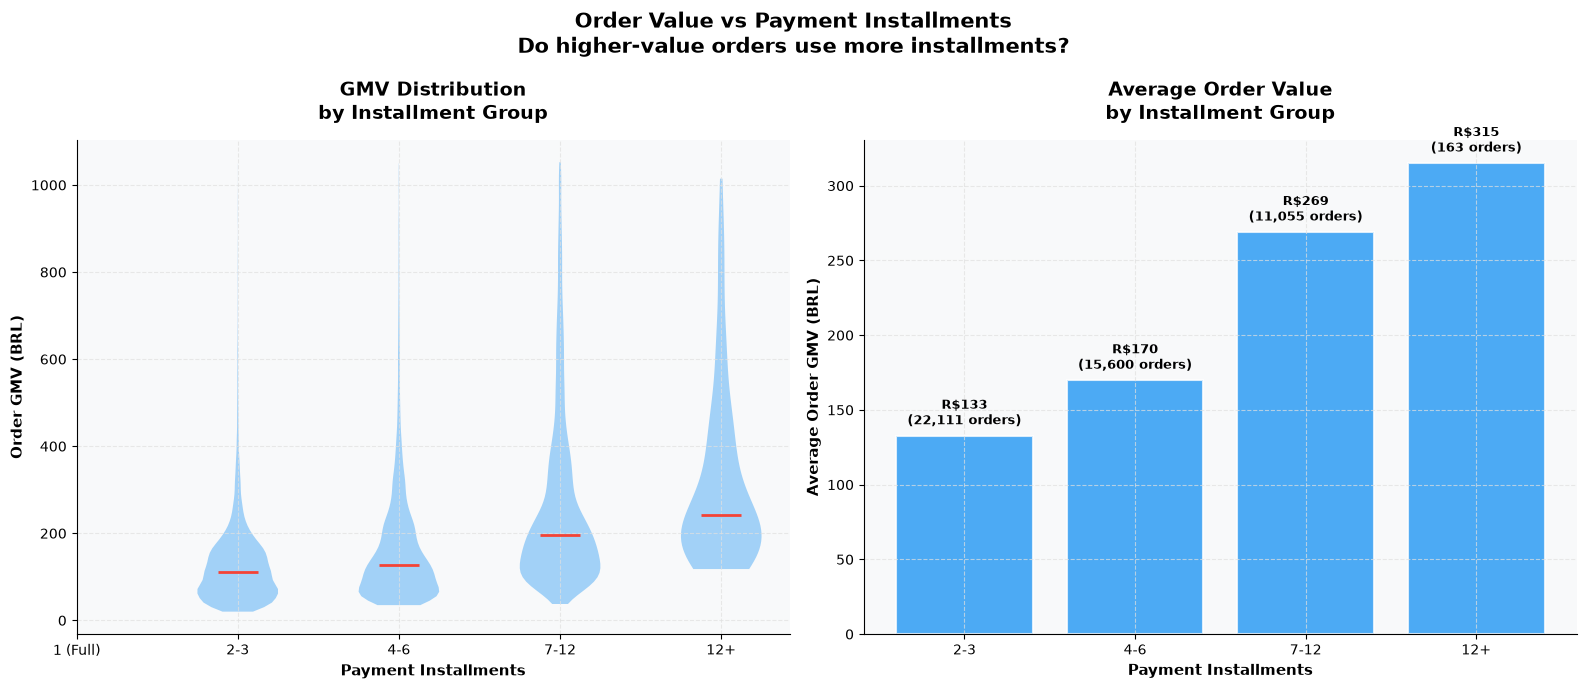


 ORDER VALUE vs INSTALLMENTS:
   2-3       : Avg GMV R$  132.58 | 22,111 orders
   4-6       : Avg GMV R$  169.69 | 15,600 orders
   7-12      : Avg GMV R$  268.87 | 11,055 orders
   12+       : Avg GMV R$  315.01 |    163 orders


In [9]:
# 3.2 ORDER VALUE vs PAYMENT INSTALLMENTS

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle(
    'Order Value vs Payment Installments\n'
    'Do higher-value orders use more installments?',
    fontsize=15, fontweight='bold'
)

install_df = df_delivered[
    df_delivered['max_installments'].notna() &
    df_delivered['total_gmv'].notna() &
    (df_delivered['total_gmv'] <= df_delivered['total_gmv'].quantile(0.99))
].copy()

install_df['installment_group'] = install_df['max_installments'].apply(
    lambda x: '1 (Full)' if x == 1
    else '2-3' if x <= 3
    else '4-6' if x <= 6
    else '7-12' if x <= 12
    else '12+'
)

order_cats = ['1 (Full)', '2-3', '4-6', '7-12', '12+']
install_df['installment_group'] = pd.Categorical(
    install_df['installment_group'], categories=order_cats, ordered=True
)

# Plot 1: Violin + Strip
ax1 = axes[0]
violin_data = [
    install_df[install_df['installment_group'] == g]['total_gmv'].dropna()
    for g in order_cats
]
parts = ax1.violinplot(
    violin_data,
    positions=range(len(order_cats)),
    showmedians=True,
    showextrema=False
)
for pc in parts['bodies']:
    pc.set_facecolor(COLORS['primary'])
    pc.set_alpha(0.4)
parts['cmedians'].set_color(COLORS['danger'])
parts['cmedians'].set_linewidth(2)

ax1.set_xticks(range(len(order_cats)))
ax1.set_xticklabels(order_cats)
ax1.set_xlabel('Payment Installments')
ax1.set_ylabel('Order GMV (BRL)')
ax1.set_title('GMV Distribution\nby Installment Group')

# Plot 2: Mean GMV & order count per installment
ax2 = axes[1]
inst_summary = install_df.groupby('installment_group', observed=True).agg(
    mean_gmv=('total_gmv', 'mean'),
    order_count=('order_id', 'count')
).reset_index()

color_bars = [COLORS['primary']] * len(inst_summary)
bars = ax2.bar(
    inst_summary['installment_group'],
    inst_summary['mean_gmv'],
    color=color_bars, alpha=0.8, edgecolor='white', linewidth=1.5
)
for bar, (_, row) in zip(bars, inst_summary.iterrows()):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        f'R${row["mean_gmv"]:.0f}\n({row["order_count"]:,} orders)',
        ha='center', va='bottom', fontsize=9, fontweight='bold'
    )

ax2.set_xlabel('Payment Installments')
ax2.set_ylabel('Average Order GMV (BRL)')
ax2.set_title('Average Order Value\nby Installment Group')

plt.tight_layout()
plt.savefig('../assets/eda/05_gmv_vs_installments.png')
plt.show()

print(f"\n ORDER VALUE vs INSTALLMENTS:")
for _, row in inst_summary.iterrows():
    print(f"   {str(row['installment_group']):10s}: "
          f"Avg GMV R${row['mean_gmv']:>8,.2f} "
          f"| {row['order_count']:>6,} orders")

Terdapat hubungan positif antara jumlah cicilan dan nilai transaksi (GMV). Rata rata GMV meningkat meningkat dari R$ 132.58 pada cicilan 2-3 kali menjadi R$315.01 pada cicilan 12+. Meskipun cicilan 2-3 kali merupakan pilihan terbanyak yaitu 45.2% dari pesanan yang dianalisis tetapi cicilan lebih panjang memiliki nilai yang lebih tinggi.

Optimalkan cicilan 2-6 kali untuk memenuhi kebutuhan mayoritas pelanggan dan mengevaluasi program cicilan 7-12 kali untuk mendukung transaksi bernilai tinggi. Segmentasi dilakukan berdasarkan kategori produk dan nilai transaksi untuk menentukan strategi pembayaran.

### 9. GMV Monthly Trend

In [10]:
query_monthly = f"""
    SELECT *
    FROM `{REPORTING_DATASET}.rpt_revenue_monthly`
    ORDER BY year_month
"""
df_monthly = run_query(client, query_monthly)
print(f"rpt_revenue_monthly: {len(df_monthly):>8,} rows")


rpt_revenue_monthly:       24 rows



MoM Growth Validation
Valid MoM observations: 20
Excluded months: ['2016-09', '2016-10', '2016-12', '2017-01']
Average displayed MoM: 9.20%


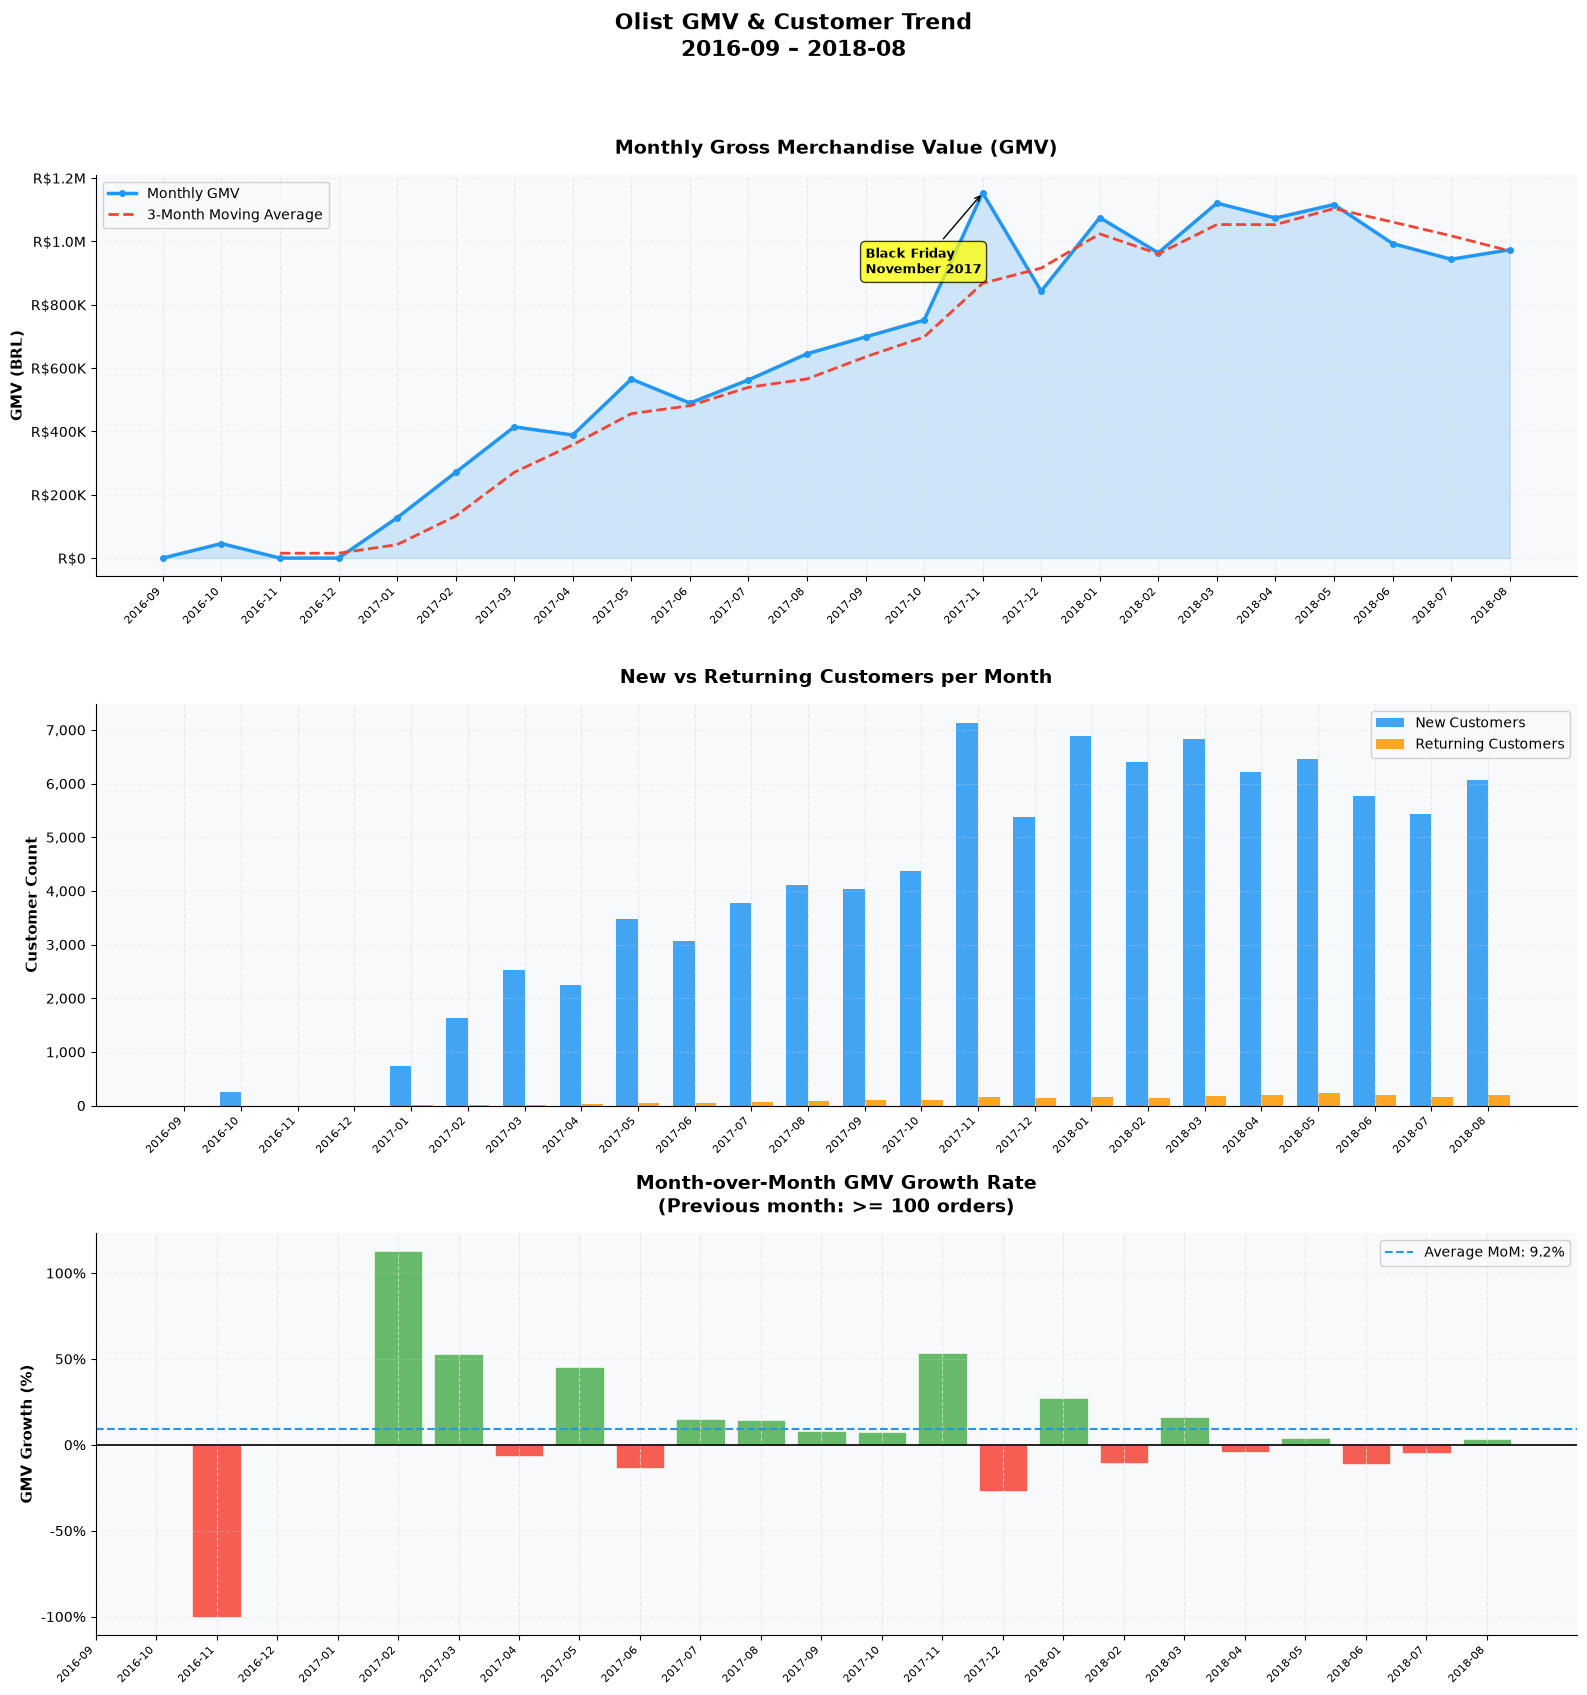

GMV TREND HIGHLIGHTS
Total observed-period GMV: R$15,212,037.88
Peak month: 2017-11
Peak GMV: R$1,153,092.66
Average MoM growth: 30937.97%
Positive-growth months: 14 / 22 valid growth observations


In [14]:

# 4.1 GMV MONTHLY TREND

required_columns = [
    'year_month',
    'total_gmv',
    'total_orders',
    'new_customers',
    'returning_customers'
]

missing_columns = [
    col for col in required_columns
    if col not in df_monthly.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

df_monthly_base = df_monthly[required_columns].copy()

parsed_month = pd.to_datetime(
    df_monthly_base['year_month'].astype(str),
    errors='coerce'
)

if parsed_month.isna().any():
    invalid_months = (
        df_monthly_base.loc[
            parsed_month.isna(), 'year_month'
        ].tolist()
    )
    raise ValueError(
        f"Invalid year_month values: {invalid_months}"
    )

df_monthly_base['year_month'] = (
    parsed_month.dt.to_period('M').dt.to_timestamp()
)

if df_monthly_base['year_month'].duplicated().any():
    duplicate_months = (
        df_monthly_base.loc[
            df_monthly_base['year_month'].duplicated(
                keep=False
            ),
            'year_month'
        ]
        .dt.strftime('%Y-%m')
        .unique()
        .tolist()
    )

    raise ValueError(
        "Duplicate monthly records detected. "
        f"Aggregate them to one row per month first: "
        f"{duplicate_months}"
    )

numeric_columns = [
    'total_gmv',
    'total_orders',
    'new_customers',
    'returning_customers'
]

for col in numeric_columns:
    df_monthly_base[col] = pd.to_numeric(
        df_monthly_base[col],
        errors='coerce'
    )

df_monthly_base = (
    df_monthly_base
    .sort_values('year_month')
    .reset_index(drop=True)
)

if df_monthly_base.empty:
    raise ValueError("df_monthly contains no valid rows.")

df_monthly_observed = df_monthly_base.copy()

full_month_index = pd.date_range(
    start=df_monthly_base['year_month'].min(),
    end=df_monthly_base['year_month'].max(),
    freq='MS'
)

df_monthly_plot = (
    df_monthly_base
    .set_index('year_month')
    .reindex(full_month_index)
)

df_monthly_plot.index.name = 'year_month'

# 2. CALCULATE MOVING AVERAGE & MOM GROWTH
df_monthly_plot['gmv_3m_moving_avg'] = (
    df_monthly_plot['total_gmv']
    .rolling(window=3, min_periods=3)
    .mean()
)

previous_month_gmv = df_monthly_plot['total_gmv'].shift(1)

df_monthly_plot['gmv_mom_growth_pct'] = (
    df_monthly_plot['total_gmv']
    .div(previous_month_gmv)
    .sub(1)
    .mul(100)
)

invalid_growth = (
    previous_month_gmv.isna()
    | previous_month_gmv.eq(0)
    | df_monthly_plot['total_gmv'].isna()
)

df_monthly_plot.loc[
    invalid_growth,
    'gmv_mom_growth_pct'
] = np.nan

df_monthly_plot['gmv_mom_growth_pct'] = (
    df_monthly_plot['gmv_mom_growth_pct']
    .replace([np.inf, -np.inf], np.nan)
)

df_monthly_plot = df_monthly_plot.reset_index()

df_monthly_plot['year_month_label'] = (
    df_monthly_plot['year_month'].dt.strftime('%Y-%m')
)

x = np.arange(len(df_monthly_plot))

x_ticks = df_monthly_plot[
    'year_month_label'
].tolist()

gmv = df_monthly_plot['total_gmv'].to_numpy(
    dtype=float
)

gmv_ma = df_monthly_plot[
    'gmv_3m_moving_avg'
].to_numpy(dtype=float)


# 3. CREATE FIGURE
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(16, 17)
)

fig.suptitle(
    'Olist GMV & Customer Trend\n'
    f'{x_ticks[0]} – {x_ticks[-1]}',
    fontsize=16,
    fontweight='bold',
    y=0.995
)


# PLOT 1: MONTHLY GMV + 3-MONTH MOVING AVERAGE
ax1 = axes[0]

valid_gmv = np.isfinite(gmv)

ax1.fill_between(
    x,
    gmv,
    0,
    where=valid_gmv,
    alpha=0.20,
    color=COLORS['primary']
)

ax1.plot(
    x,
    gmv,
    color=COLORS['primary'],
    linewidth=2.5,
    marker='o',
    markersize=4,
    label='Monthly GMV'
)

ax1.plot(
    x,
    gmv_ma,
    color=COLORS['danger'],
    linewidth=2,
    linestyle='--',
    label='3-Month Moving Average'
)

bf_mask = (
    df_monthly_plot['year_month_label'].eq('2017-11')
    & df_monthly_plot['total_gmv'].notna()
)

bf_positions = np.flatnonzero(bf_mask.to_numpy())

if len(bf_positions) > 0:
    bf_pos = int(bf_positions[0])
    bf_val = gmv[bf_pos]

    ax1.annotate(
        'Black Friday\nNovember 2017',
        xy=(bf_pos, bf_val),
        xytext=(
            max(0, bf_pos - 2),
            bf_val * 0.78
        ),
        fontsize=9,
        fontweight='bold',
        arrowprops={
            'arrowstyle': '->',
            'color': 'black'
        },
        bbox={
            'boxstyle': 'round,pad=0.4',
            'facecolor': 'yellow',
            'alpha': 0.75
        }
    )

ax1.set_ylabel('GMV (BRL)')
ax1.set_title('Monthly Gross Merchandise Value (GMV)')
ax1.legend(loc='best')
ax1.grid(axis='y', alpha=0.25)

# Currency formatter
def format_brl(value, _):
    if abs(value) >= 1_000_000:
        return f'R${value / 1_000_000:.1f}M'
    elif abs(value) >= 1_000:
        return f'R${value / 1_000:.0f}K'
    return f'R${value:,.0f}'

ax1.yaxis.set_major_formatter(
    mticker.FuncFormatter(format_brl)
)

ax1.set_xticks(x)
ax1.set_xticklabels(
    x_ticks,
    rotation=45,
    ha='right',
    fontsize=8
)


# PLOT 2: NEW VS RETURNING CUSTOMERS
ax2 = axes[1]

width = 0.38

new_customers = df_monthly_plot[
    'new_customers'
].to_numpy(dtype=float)

returning_customers = df_monthly_plot[
    'returning_customers'
].to_numpy(dtype=float)

ax2.bar(
    x - width / 2,
    new_customers,
    width=width,
    color=COLORS['primary'],
    alpha=0.85,
    label='New Customers'
)

ax2.bar(
    x + width / 2,
    returning_customers,
    width=width,
    color=COLORS['secondary'],
    alpha=0.85,
    label='Returning Customers'
)

ax2.set_ylabel('Customer Count')
ax2.set_title('New vs Returning Customers per Month')
ax2.legend(loc='best')
ax2.grid(axis='y', alpha=0.25)

ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda value, _: f'{value:,.0f}'
    )
)

ax2.set_xticks(x)
ax2.set_xticklabels(
    x_ticks,
    rotation=45,
    ha='right',
    fontsize=8
)


# PLOT 3: MONTH-OVER-MONTH GMV GROWTH
ax3 = axes[2]

MIN_PREVIOUS_MONTH_ORDERS = 100

current_gmv = df_monthly_plot['total_gmv']
previous_gmv = current_gmv.shift(1)

previous_orders = (
    df_monthly_plot['total_orders'].shift(1)
)

current_orders = df_monthly_plot['total_orders']

mom_growth = (
    (current_gmv - previous_gmv)
    / previous_gmv.where(previous_gmv > 0)
    * 100
)

valid_mom = (
    previous_gmv.gt(0)
    & previous_orders.ge(MIN_PREVIOUS_MONTH_ORDERS)
    & current_gmv.notna()
    & current_orders.notna()
    & np.isfinite(mom_growth)
)

mom_growth = mom_growth.where(valid_mom)

valid_positions = np.flatnonzero(
    mom_growth.notna().to_numpy()
)

valid_values = mom_growth.dropna().to_numpy()

bar_colors = [
    COLORS['success'] if value >= 0
    else COLORS['danger']
    for value in valid_values
]

ax3.bar(
    valid_positions,
    valid_values,
    color=bar_colors,
    alpha=0.85,
    edgecolor='white',
    linewidth=0.5
)

ax3.axhline(
    0,
    color='black',
    linewidth=1.2
)

if len(valid_values) > 0:
    avg_mom = valid_values.mean()

    ax3.axhline(
        avg_mom,
        color=COLORS['primary'],
        linestyle='--',
        linewidth=1.5,
        label=f'Average MoM: {avg_mom:.1f}%'
    )

    ax3.legend(loc='best')

ax3.set_title(
    'Month-over-Month GMV Growth Rate\n'
    f'(Previous month: >= '
    f'{MIN_PREVIOUS_MONTH_ORDERS} orders)'
)

ax3.set_ylabel('GMV Growth (%)')

ax3.set_xticks(x)
ax3.set_xticklabels(
    x_ticks,
    rotation=45,
    ha='right',
    fontsize=8
)

ax3.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda value, _: f'{value:,.0f}%'
    )
)

ax3.grid(axis='y', alpha=0.25)

excluded_months = df_monthly_plot.loc[
    mom_growth.isna(),
    'year_month'
].dt.strftime('%Y-%m').tolist()

print('\nMoM Growth Validation')
print(f'Valid MoM observations: {len(valid_values)}')
print(f'Excluded months: {excluded_months}')

if len(valid_values) > 0:
    print(f'Average displayed MoM: {avg_mom:.2f}%')


# 4. FINAL LAYOUT & EXPORT
plt.tight_layout(rect=[0, 0, 1, 0.97])

output_path = Path(
    '../assets/eda/06_gmv_monthly_trend.png'
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# 5. GMV TREND SUMMARY
valid_observed_gmv = df_monthly_observed[
    'total_gmv'
].dropna()

valid_peak_data = df_monthly_observed.dropna(
    subset=['total_gmv']
)

valid_growth_summary = df_monthly_plot[
    'gmv_mom_growth_pct'
].dropna()

print('GMV TREND HIGHLIGHTS')

if not valid_observed_gmv.empty:
    total_gmv = valid_observed_gmv.sum()

    print(
        f'Total observed-period GMV: '
        f'R${total_gmv:,.2f}'
    )

if not valid_peak_data.empty:
    peak_idx = valid_peak_data[
        'total_gmv'
    ].idxmax()

    peak_row = valid_peak_data.loc[peak_idx]

    print(
        f"Peak month: {peak_row['year_month']:%Y-%m}"
    )

    print(
        f"Peak GMV: R${peak_row['total_gmv']:,.2f}"
    )

if not valid_growth_summary.empty:
    print(
        f'Average MoM growth: '
        f'{valid_growth_summary.mean():.2f}%'
    )

    positive_months = (
        valid_growth_summary > 0
    ).sum()

    print(
        f'Positive-growth months: '
        f'{positive_months} / '
        f'{len(valid_growth_summary)} '
        f'valid growth observations'
    )
else:
    print('MoM growth: Insufficient valid data.')

missing_calendar_months = (
    df_monthly_plot['total_gmv'].isna().sum()
)

if missing_calendar_months > 0:
    print(
        f'Calendar months without GMV data: '
        f'{missing_calendar_months}'
    )

Olist mengalami pertumbuhan GMV yang signifikan sepanjang 2017, dengan salah satu puncak tertinggi mencapai sekitar R$1,15 juta pada November 2017, bertepatan dengan Black Friday. Namun, pertumbuhan mulai melambat pada 2018 dengan GMV bulanan relatif stabil di kisaran R$900.000–R$1,1 juta. Rata rata pertumbuhan GMV bulanan tercatat sebesar 9,2%. Dari sisi pelanggan, pertumbuhan didominasi oleh pelanggan baru, sedangkan jumlah pelanggan yang melakukan pembelian berulang masih sangat rendah.

Olist perlu menyeimbangkan strategi akuisisi pelanggan dengan peningkatan retensi dan frekuensi pembelian. Optimalisasi kampanye musiman, program loyalitas, serta strategi peningkatan Average Order Value (AOV) dapat menjadi prioritas untuk mendorong pertumbuhan bisnis yang lebih berkelanjutan.

In [15]:

# Diagnose extreme MoM growth
diagnostic = df_monthly_plot[
    [
        'year_month',
        'total_gmv',
        'total_orders',
        'gmv_mom_growth_pct'
    ]
].copy()

diagnostic['previous_gmv'] = (
    diagnostic['total_gmv'].shift(1)
)

diagnostic['previous_orders'] = (
    diagnostic['total_orders'].shift(1)
)

diagnostic['year_month'] = pd.to_datetime(
    diagnostic['year_month']
).dt.strftime('%Y-%m')

print(
    diagnostic[
        [
            'year_month',
            'previous_gmv',
            'total_gmv',
            'previous_orders',
            'total_orders',
            'gmv_mom_growth_pct'
        ]
    ].to_string(
        index=False,
        formatters={
            'previous_gmv': lambda v: f'{v:,.4f}',
            'total_gmv': lambda v: f'{v:,.4f}',
            'gmv_mom_growth_pct': lambda v: (
                f'{v:,.2f}%' if pd.notna(v) else 'N/A'
            )
        }
    )
)


year_month   previous_gmv      total_gmv  previous_orders  total_orders gmv_mom_growth_pct
   2016-09            NaN       143.4600             <NA>             1                NaN
   2016-10       143.4600    45,831.8200                1           261         31,847.46%
   2016-11    45,831.8200         0.0000              261             0           -100.00%
   2016-12         0.0000        19.6200                0             1                NaN
   2017-01        19.6200   127,275.7200                1           749        648,603.98%
   2017-02   127,275.7200   270,655.3300              749          1650            112.65%
   2017-03   270,655.3300   414,216.8800             1650          2545             53.04%
   2017-04   414,216.8800   388,491.2900             2545          2279             -6.21%
   2017-05   388,491.2900   565,268.5600             2279          3531             45.50%
   2017-06   565,268.5600   489,324.8700             3531          3130            -13.43%

### 10. DayofWeek and Hourly Pattern

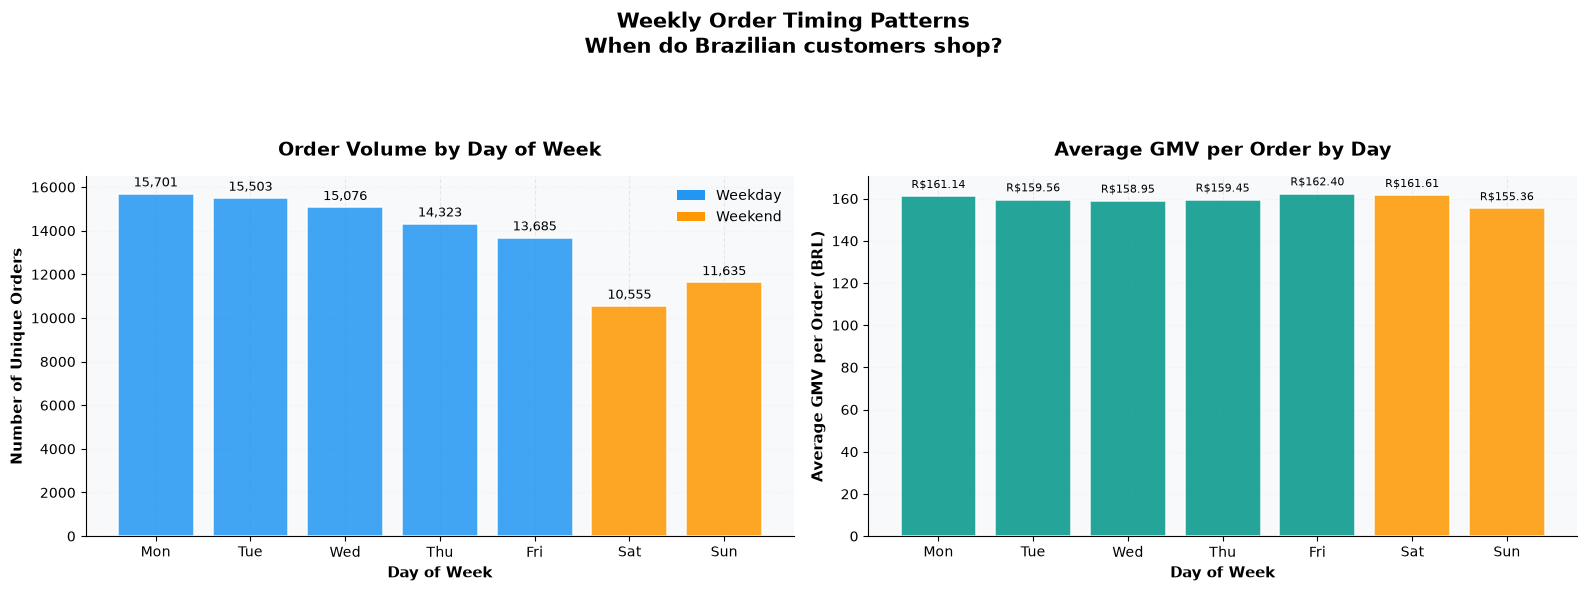


WEEKLY ORDER PATTERN
----------------------------------------
Mon:  15,701 orders ( 16.3%) | Average GMV: R$161.14
Tue:  15,503 orders ( 16.1%) | Average GMV: R$159.56
Wed:  15,076 orders ( 15.6%) | Average GMV: R$158.95
Thu:  14,323 orders ( 14.8%) | Average GMV: R$159.45
Fri:  13,685 orders ( 14.2%) | Average GMV: R$162.40
Sat:  10,555 orders ( 10.9%) | Average GMV: R$161.61
Sun:  11,635 orders ( 12.1%) | Average GMV: R$155.36


In [16]:
# 1. Define day mapping
day_map = {
    1: 'Sun', 2: 'Mon', 3: 'Tue', 4: 'Wed',
    5: 'Thu', 6: 'Fri', 7: 'Sat'
}

dow_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
weekend_days = ['Sat', 'Sun']

# 2. Prepare analysis data
required_cols = [
    'order_id', 'purchase_day_of_week', 'total_gmv'
]
missing_cols = set(required_cols) - set(df_delivered.columns)

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

df_weekly = df_delivered[
    ['order_id', 'purchase_day_of_week', 'total_gmv']
].copy()

if df_weekly['order_id'].duplicated().any():
    raise ValueError(
        "df_delivered contains duplicate order_id values. "
        "Aggregate to one row per order before calculating "
        "order counts and average GMV."
    )

invalid_days = ~df_weekly['purchase_day_of_week'].isin(day_map.keys())

if invalid_days.any():
    raise ValueError(
        "Unexpected purchase_day_of_week codes. "
        "Verify the source convention before mapping."
    )

df_weekly['day_name'] = (
    df_weekly['purchase_day_of_week'].map(day_map)
)

# Convert GMV to numeric
df_weekly['total_gmv'] = pd.to_numeric(
    df_weekly['total_gmv'], errors='coerce'
)

# Count orders by day
dow_counts = (
    df_weekly.groupby('day_name')['order_id']
    .nunique()
    .reindex(dow_order, fill_value=0)
)

dow_gmv_mean = (
    df_weekly.groupby('day_name')['total_gmv']
    .mean()
    .reindex(dow_order)
)

# 3. Create visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

fig.suptitle(
    'Weekly Order Timing Patterns\n'
    'When do Brazilian customers shop?',
    fontsize=15,
    fontweight='bold'
)

# Chart 1: Order count
ax1 = axes[0]

bar_colors = [
    COLORS['secondary'] if d in weekend_days
    else COLORS['primary']
    for d in dow_order
]

bars = ax1.bar(
    dow_order,
    dow_counts.values,
    color=bar_colors,
    alpha=0.85,
    edgecolor='white',
    linewidth=1.2
)

ax1.bar_label(
    bars,
    labels=[f'{v:,.0f}' for v in dow_counts.values],
    padding=3,
    fontsize=9
)

ax1.set_xlabel('Day of Week')
ax1.set_ylabel('Number of Unique Orders')
ax1.set_title('Order Volume by Day of Week')
ax1.grid(axis='y', alpha=0.2)
ax1.set_axisbelow(True)

weekday_patch = mpatches.Patch(
    facecolor=COLORS['primary'], label='Weekday'
)
weekend_patch = mpatches.Patch(
    facecolor=COLORS['secondary'], label='Weekend'
)

ax1.legend(handles=[weekday_patch, weekend_patch], frameon=False)

# Chart 2: Average GMV per order
ax2 = axes[1]

bar_colors2 = [
    COLORS['secondary'] if d in weekend_days
    else COLORS['teal']
    for d in dow_order
]

bars2 = ax2.bar(
    dow_order,
    dow_gmv_mean.values,
    color=bar_colors2,
    alpha=0.85,
    edgecolor='white',
    linewidth=1.2
)

# Format labels based on chart scale
for bar, value in zip(bars2, dow_gmv_mean.values):
    if pd.notna(value):
        ax2.annotate(
            f'R${value:,.2f}',
            xy=(bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 4),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=8
        )

ax2.set_xlabel('Day of Week')
ax2.set_ylabel('Average GMV per Order (BRL)')
ax2.set_title('Average GMV per Order by Day')
ax2.grid(axis='y', alpha=0.2)
ax2.set_axisbelow(True)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.savefig(
    '../assets/eda/07_weekly_pattern.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

# 4. Print order distribution
total_orders = dow_counts.sum()

print('\nWEEKLY ORDER PATTERN')
print('-' * 40)

for day in dow_order:
    count = dow_counts[day]
    pct = count / total_orders * 100 if total_orders else 0
    avg_gmv = dow_gmv_mean[day]

    avg_text = (
        f'R${avg_gmv:,.2f}'
        if pd.notna(avg_gmv) else 'N/A'
    )

    print(
        f'{day}: {count:>7,} orders '
        f'({pct:5.1f}%) | Average GMV: {avg_text}'
    )


Aktivitas pembelian pelanggan Olist lebih tinggi pada hari kerja, terutama Senin yang mencatat volume tertinggi sebanyak 15.701 pesanan. Sebaliknya, Sabtu memiliki volume terendah sebanyak 10.555 pesanan. Walaupun terdapat perbedaan volume transaksi, Average Order Value (AOV) relatif stabil sepanjang minggu pada kisaran R$155–R$162, dengan nilai tertinggi pada Jumat sebesar R$162,40.

Optimalkan waktu pelaksanaan kampanye pemasaran dan alokasi sumber daya operasional berdasarkan pola transaksi mingguan. Fokus pada pemanfaatan aktivitas tinggi di awal minggu serta pengujian promosi akhir pekan untuk meningkatkan volume pesanan.

In [17]:
print("Total rows:", len(df_delivered))
print("Unique orders:", df_delivered['order_id'].nunique())
print("Duplicate order IDs:", df_delivered['order_id'].duplicated().sum())

assert df_delivered['order_id'].notna().all(), \
    "Found NULL order_id values"

assert not df_delivered['order_id'].duplicated().any(), \
    "fact_orders contains duplicate order_id values"

Total rows: 96478
Unique orders: 96478
Duplicate order IDs: 0


In [18]:
# Order volume per day
dow_counts = (
    df_delivered
    .groupby(df_delivered['purchase_day_of_week'].map(day_map))
    ['order_id']
    .nunique()
    .reindex(dow_order, fill_value=0)
)

# Average GMV per order by day
dow_gmv_mean = (
    df_delivered.assign(
        day_name=df_delivered['purchase_day_of_week'].map(day_map)
    )
    .groupby('day_name')['total_gmv']
    .mean()
    .reindex(dow_order)
)

### 11. Geographic Analysis

In [19]:

# 5.0 PREPARE GEOGRAPHIC DELIVERY DATA
query_delivery = """
WITH order_state AS (
    SELECT
        o.order_id,
        d.customer_state,
        d.customer_region,
        o.is_delivered,
        o.is_ontime_delivery

    FROM
        `olist-ecommerce-analytics-1.olist_intermediate.int_orders` AS o

    INNER JOIN
        `olist-ecommerce-analytics-1.olist_staging.stg_customers` AS c
        ON o.customer_id = c.customer_id

    INNER JOIN
        `olist-ecommerce-analytics-1.olist_mart.dim_customers` AS d
        ON c.customer_unique_id = d.customer_unique_id
),

state_metrics AS (
    SELECT
        customer_state,
        customer_region,

        -- Order volume
        COUNT(DISTINCT order_id) AS total_orders,

        -- Orders eligible for OTDR measurement:
        -- delivered orders with a known on-time status
        COUNT(DISTINCT IF(
            is_delivered IS TRUE
            AND is_ontime_delivery IS NOT NULL,
            order_id,
            NULL
        )) AS eligible_delivery_orders,

        -- Orders delivered on time
        COUNT(DISTINCT IF(
            is_delivered IS TRUE
            AND is_ontime_delivery IS TRUE,
            order_id,
            NULL
        )) AS ontime_orders

    FROM order_state

    GROUP BY
        customer_state,
        customer_region
)

SELECT
    customer_state,
    customer_region,
    total_orders,
    eligible_delivery_orders,
    ontime_orders,

    SAFE_DIVIDE(
        ontime_orders,
        eligible_delivery_orders
    ) * 100 AS avg_otdr_pct

FROM state_metrics
ORDER BY total_orders DESC
"""

df_delivery = run_query(client, query_delivery)

print(f"State-level rows: {len(df_delivery):,}")
print(
    "Unique states:",
    df_delivery['customer_state'].nunique()
)
print(df_delivery.head())

State-level rows: 27
Unique states: 27
  customer_state customer_region  total_orders  eligible_delivery_orders  \
0             sp       Southeast         41748                     40497   
1             rj       Southeast         12858                     12358   
2             mg       Southeast         11637                     11358   
3             rs           South          5464                      5342   
4             pr           South          5045                      4923   

   ontime_orders  avg_otdr_pct  
0          38110     94.105736  
1          10693     86.526946  
2          10718     94.365205  
3           4960     92.849120  
4           4677     95.003047  


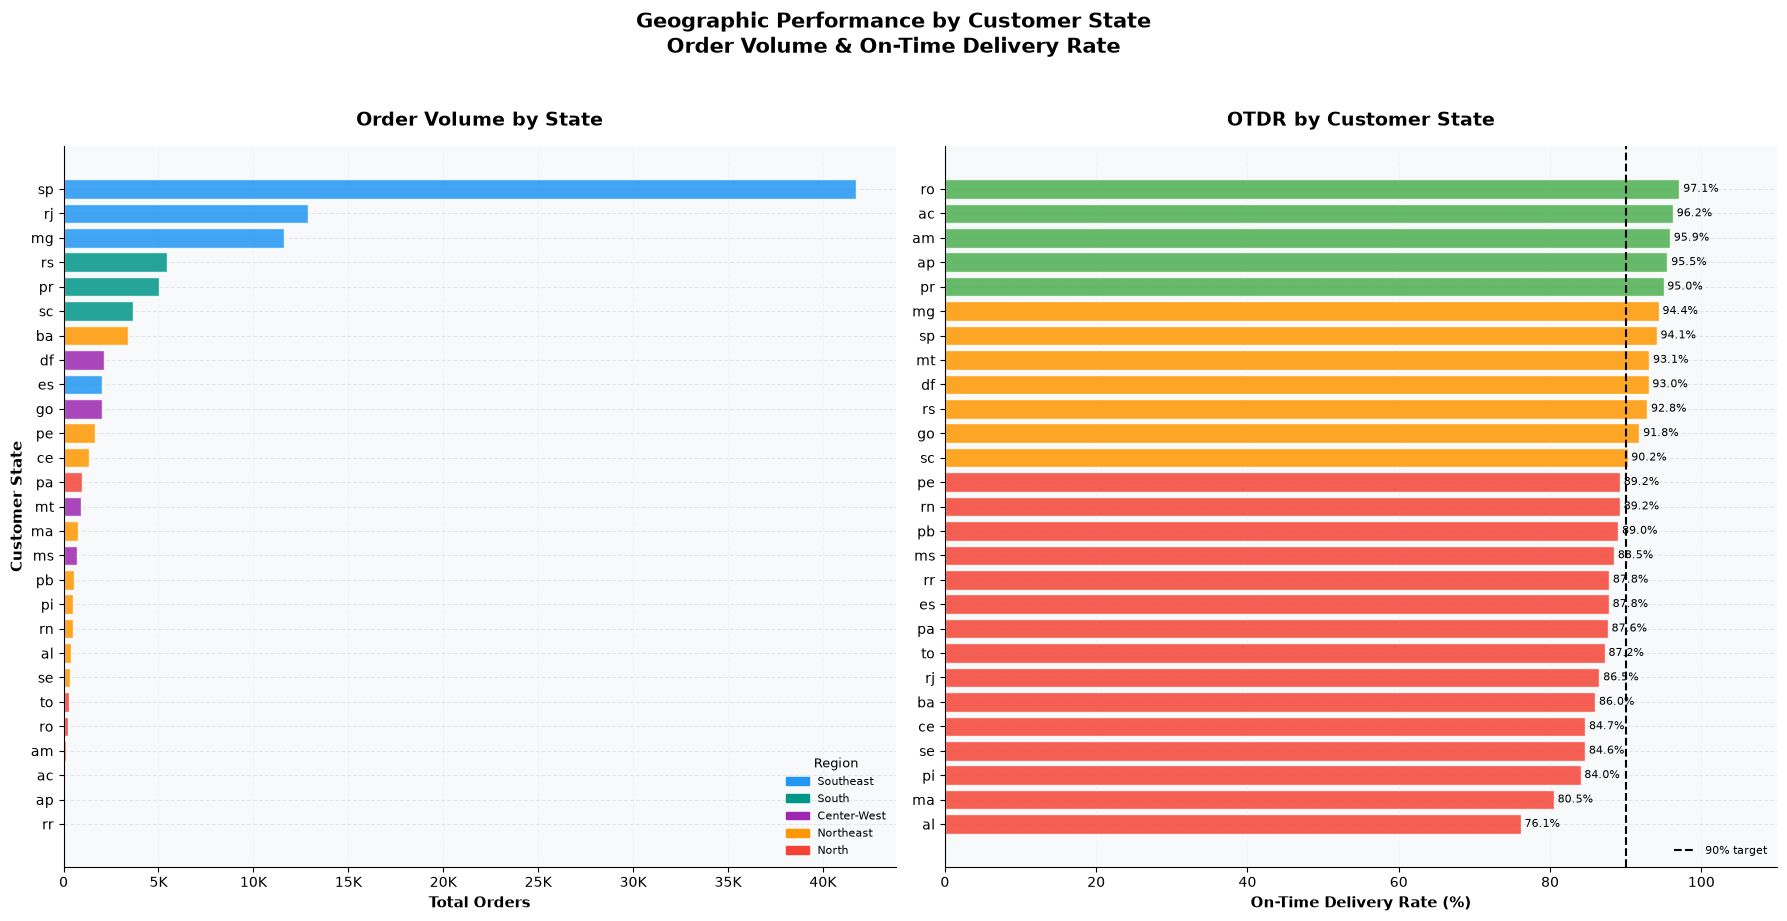


GEOGRAPHIC HIGHLIGHTS

Top 3 states by order volume:
  sp: 41,748 orders
  rj: 12,858 orders
  mg: 11,637 orders

Best OTDR state: ro (97.1%)
Worst OTDR state: al (76.1%)

States below 90% OTDR target: 15 of 27

Total eligible delivery orders: 96,476
Total on-time orders: 88,649


In [20]:

# 5.1 GEOGRAPHIC — ORDER VOLUME & OTDR PER STATE

required_cols = [
    'customer_state',
    'customer_region',
    'total_orders',
    'eligible_delivery_orders',
    'ontime_orders',
    'avg_otdr_pct'
]

missing_cols = set(required_cols) - set(df_delivery.columns)

if missing_cols:
    raise ValueError(
        f"Missing required columns: {sorted(missing_cols)}"
    )

df_geo = df_delivery.copy()

numeric_cols = [
    'total_orders',
    'eligible_delivery_orders',
    'ontime_orders',
    'avg_otdr_pct'
]

for col in numeric_cols:
    df_geo[col] = pd.to_numeric(
        df_geo[col], errors='coerce'
    )

df_geo = df_geo.dropna(
    subset=['customer_state', 'total_orders']
)

if df_geo.empty:
    raise ValueError("No valid state-level data available.")

duplicate_states = df_geo['customer_state'].duplicated(
    keep=False
)

if duplicate_states.any():
    duplicated = (
        df_geo.loc[duplicate_states, 'customer_state']
        .unique()
        .tolist()
    )
    raise ValueError(
        "Multiple rows found per state. Check customer_region "
        f"consistency before plotting: {duplicated}"
    )

# Validate OTDR
invalid_otdr = (
    df_geo['avg_otdr_pct'].notna()
    & ~df_geo['avg_otdr_pct'].between(0, 100)
)

if invalid_otdr.any():
    raise ValueError(
        "OTDR values outside 0–100%. Check the SQL calculation."
    )

region_colors = {
    'Southeast': COLORS['primary'],
    'South': COLORS['teal'],
    'Center-West': COLORS['purple'],
    'Northeast': COLORS['secondary'],
    'North': COLORS['danger']
}

default_color = COLORS['primary']


fig, axes = plt.subplots(1, 2, figsize=(18, 9))

fig.suptitle(
    'Geographic Performance by Customer State\n'
    'Order Volume & On-Time Delivery Rate',
    fontsize=15,
    fontweight='bold',
    y=1.02
)

# 4. PLOT 1 — ORDER VOLUME
df_volume = df_geo.sort_values(
    'total_orders', ascending=True
)

ax1 = axes[0]

colors_vol = [
    region_colors.get(region, default_color)
    for region in df_volume['customer_region']
]

ax1.barh(
    df_volume['customer_state'],
    df_volume['total_orders'],
    color=colors_vol,
    alpha=0.85,
    edgecolor='white'
)

ax1.set_xlabel('Total Orders')
ax1.set_ylabel('Customer State')
ax1.set_title('Order Volume by State', fontweight='bold')

ax1.xaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda x, _: (
            f'{x / 1e3:.0f}K'
            if x >= 1000 else f'{x:.0f}'
        )
    )
)

ax1.grid(axis='x', linestyle='--', alpha=0.25)
ax1.set_axisbelow(True)

legend_patches = [
    mpatches.Patch(color=color, label=region)
    for region, color in region_colors.items()
    if region in df_volume['customer_region'].dropna().unique()
]

if legend_patches:
    ax1.legend(
        handles=legend_patches,
        title='Region',
        loc='lower right',
        fontsize=8,
        title_fontsize=9,
        frameon=False
    )

# 5. PLOT 2 — OTDR
df_otdr = (
    df_geo.dropna(subset=['avg_otdr_pct'])
    .sort_values('avg_otdr_pct', ascending=True)
)

ax2 = axes[1]

if df_otdr.empty:
    ax2.text(
        0.5, 0.5,
        'No valid OTDR data available',
        ha='center',
        va='center',
        transform=ax2.transAxes
    )
    ax2.set_title('OTDR by Customer State', fontweight='bold')
    ax2.set_axis_off()

else:
    otdr_colors = [
        COLORS['success'] if value >= 95
        else COLORS['secondary'] if value >= 90
        else COLORS['danger']
        for value in df_otdr['avg_otdr_pct']
    ]

    bars2 = ax2.barh(
        df_otdr['customer_state'],
        df_otdr['avg_otdr_pct'],
        color=otdr_colors,
        alpha=0.85,
        edgecolor='white'
    )

    for bar, value in zip(
        bars2, df_otdr['avg_otdr_pct']
    ):
        ax2.text(
            value + 0.5,
            bar.get_y() + bar.get_height() / 2,
            f'{value:.1f}%',
            ha='left',
            va='center',
            fontsize=8
        )

    ax2.set_xlabel('On-Time Delivery Rate (%)')
    ax2.set_title('OTDR by Customer State', fontweight='bold')

    # Consistent percentage scale
    ax2.set_xlim(0, 110)

    ax2.axvline(
        90,
        color='black',
        linestyle='--',
        linewidth=1.5,
        label='90% target'
    )

    ax2.legend(
        loc='lower right',
        fontsize=8,
        frameon=False
    )

    ax2.grid(axis='x', linestyle='--', alpha=0.25)
    ax2.set_axisbelow(True)


plt.tight_layout()

plt.savefig(
    '../assets/eda/08_geographic_performance.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

# 7. GEOGRAPHIC HIGHLIGHTS
print('\nGEOGRAPHIC HIGHLIGHTS')
print('=' * 45)

top3 = df_geo.nlargest(3, 'total_orders')

print('\nTop 3 states by order volume:')

for _, row in top3.iterrows():
    print(
        f"  {row['customer_state']}: "
        f"{row['total_orders']:,.0f} orders"
    )

valid_otdr = df_geo.dropna(
    subset=['avg_otdr_pct']
)

if not valid_otdr.empty:
    best = valid_otdr.loc[
        valid_otdr['avg_otdr_pct'].idxmax()
    ]

    worst = valid_otdr.loc[
        valid_otdr['avg_otdr_pct'].idxmin()
    ]

    print(
        f"\nBest OTDR state: {best['customer_state']} "
        f"({best['avg_otdr_pct']:.1f}%)"
    )

    print(
        f"Worst OTDR state: {worst['customer_state']} "
        f"({worst['avg_otdr_pct']:.1f}%)"
    )

    below_target = (
        valid_otdr['avg_otdr_pct'] < 90
    ).sum()

    print(
        f"\nStates below 90% OTDR target: "
        f"{below_target} of {len(valid_otdr)}"
    )

else:
    print('\nNo valid OTDR values available.')

print(
    f"\nTotal eligible delivery orders: "
    f"{df_geo['eligible_delivery_orders'].sum():,.0f}"
)

print(
    f"Total on-time orders: "
    f"{df_geo['ontime_orders'].sum():,.0f}"
)


Volume pesanan Olist sangat terkonsentrasi di wilayah Southeast Brasil, terutama São Paulo dengan sekitar 42.000 pesanan dan OTDR sebesar 94,1%. Namun, Rio de Janeiro sebagai pasar terbesar kedua memiliki OTDR sebesar 86,9%, masih di bawah target 90%. Secara keseluruhan, hanya 12 dari 27 state yang memenuhi target ketepatan waktu pengiriman. Perbedaan OTDR antarwilayah menunjukkan adanya ketidakkonsistenan performa logistik.

Prioritaskan peningkatan OTDR pada wilayah dengan volume pesanan tinggi dan performa di bawah target, khususnya Rio de Janeiro. Selain itu, evaluasi kendala logistik pada state dengan OTDR terendah serta implementasikan pemantauan KPI pengiriman berdasarkan wilayah.

### 12. Outlier Detection

In [21]:
query_items = f"""
    SELECT
        order_id,
        order_item_id,
        product_id,
        seller_id,
        customer_unique_id,
        purchase_date,
        purchase_year,
        purchase_month,
        purchase_year_month,
        is_revenue_generating,
        product_category_name_english,
        product_super_category,
        customer_state,
        customer_region,
        seller_state,
        seller_region,
        price,
        freight_value,
        item_gmv,
        freight_to_price_pct,
        review_score,
        purchase_to_delivery_days
    FROM `{MART_DATASET}.fact_order_items`
    WHERE is_revenue_generating = TRUE
"""
df_items = run_query(client, query_items)
df_items['purchase_date'] = pd.to_datetime(df_items['purchase_date'])
print(f"fact_order_items loaded: {len(df_items):>8,} rows")

fact_order_items loaded:  110,197 rows


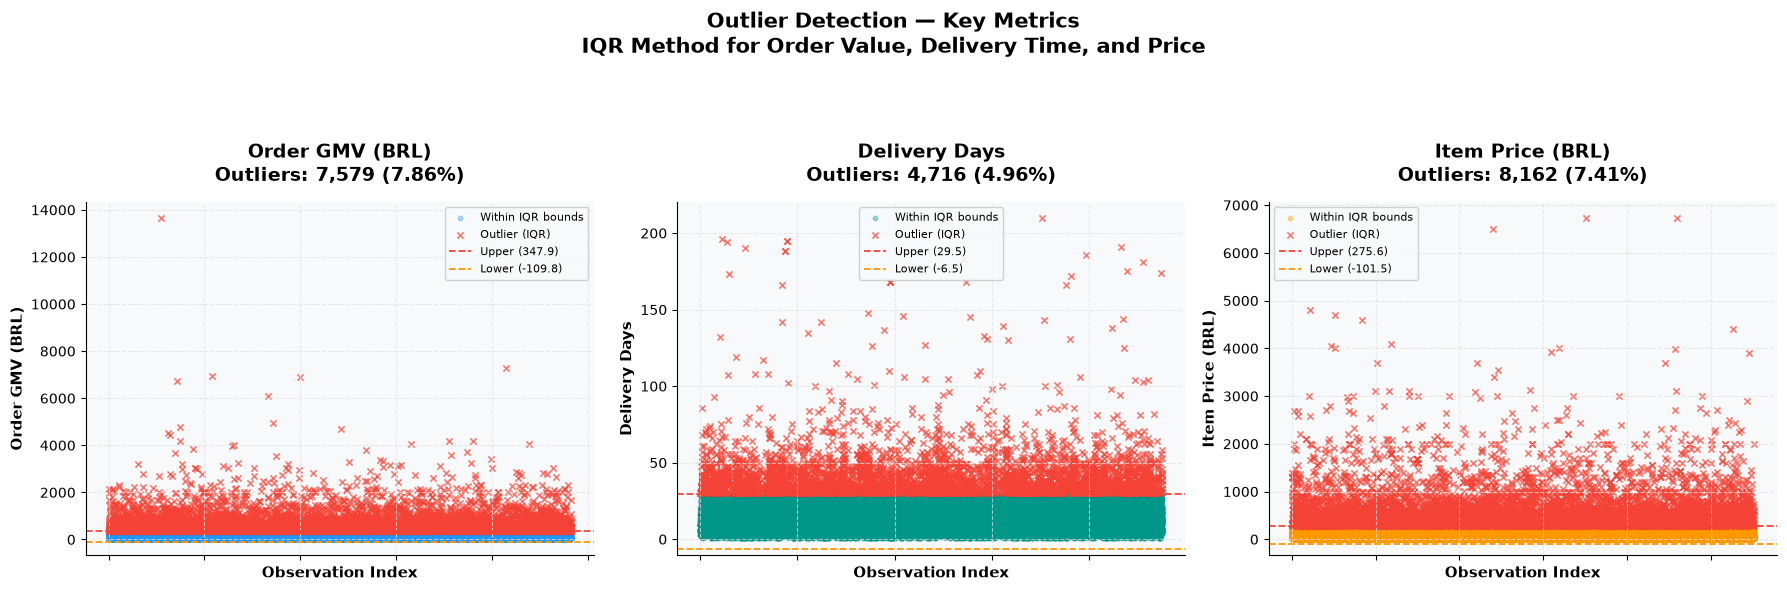


OUTLIER SUMMARY — IQR METHOD
          Metric  Valid N  Outliers Outlier (%)    Q1 Median     Q3 Lower Bound Upper Bound Max Value
 Order GMV (BRL)    96478      7579       7.86% 61.85 105.28 176.26     -109.77      347.88 13,664.08
   Delivery Days    95097      4716       4.96%  7.00  10.00  16.00       -6.50       29.50    210.00
Item Price (BRL)   110197      8162       7.41% 39.90  74.90 134.17     -101.50      275.57  6,735.00


In [22]:

# 6.1 OUTLIER DETECTION
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

gmv = pd.to_numeric(
    df_delivered['total_gmv'], errors='coerce'
)

# hanya order yang tidak terindikasi anomaly
delivery_mask = (
    df_delivered['purchase_to_delivery_days'].notna()
    & df_delivered['is_order_date_anomaly'].eq(False)
)

delivery = pd.to_numeric(
    df_delivered.loc[
        delivery_mask, 'purchase_to_delivery_days'
    ],
    errors='coerce'
)

# Item price: satu observasi per order item
price = pd.to_numeric(
    df_items['price'], errors='coerce'
)

metrics = [
    (gmv, 'Order GMV (BRL)', COLORS['primary']),
    (delivery, 'Delivery Days', COLORS['teal']),
    (price, 'Item Price (BRL)', COLORS['secondary'])
]


# 1. IQR FUNCTION
def detect_iqr_outliers(series: pd.Series):
    """
    Menghitung batas IQR dan mendeteksi outlier.
    Non-finite values diperlakukan sebagai data tidak valid.
    """
    data = pd.to_numeric(series, errors='coerce')
    data = data.replace([np.inf, -np.inf], np.nan).dropna()

    if data.empty:
        return np.nan, np.nan, pd.Series(
            False, index=data.index, dtype=bool
        )

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_mask = (data < lower) | (data > upper)

    return lower, upper, outlier_mask


# 2. VISUALIZE OUTLIERS
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

fig.suptitle(
    'Outlier Detection — Key Metrics\n'
    'IQR Method for Order Value, Delivery Time, and Price',
    fontsize=15,
    fontweight='bold'
)

summary = []

for ax, (data, label, color) in zip(axes, metrics):

    # Remove missing and non-finite values
    data_clean = pd.to_numeric(
        data, errors='coerce'
    ).replace([np.inf, -np.inf], np.nan).dropna()

    n_valid = len(data_clean)

    if n_valid == 0:
        ax.set_title(f'{label}\nNo valid data')
        ax.set_axis_off()

        summary.append({
            'Metric': label,
            'Valid N': 0,
            'Outliers': 0,
            'Outlier (%)': np.nan,
            'Q1': np.nan,
            'Median': np.nan,
            'Q3': np.nan,
            'Lower Bound': np.nan,
            'Upper Bound': np.nan,
            'Max Value': np.nan
        })
        continue

    lower, upper, is_outlier = detect_iqr_outliers(data_clean)

    x = np.arange(n_valid)
    normal_mask = ~is_outlier.to_numpy()
    outlier_mask = is_outlier.to_numpy()

    ax.scatter(
        x[normal_mask],
        data_clean.to_numpy()[normal_mask],
        color=color,
        alpha=0.35,
        s=10,
        label='Within IQR bounds'
    )

    ax.scatter(
        x[outlier_mask],
        data_clean.to_numpy()[outlier_mask],
        color=COLORS['danger'],
        alpha=0.7,
        s=20,
        marker='x',
        linewidths=1.2,
        label='Outlier (IQR)'
    )

    # Statistical thresholds
    ax.axhline(
        upper,
        color=COLORS['danger'],
        linestyle='--',
        linewidth=1.3,
        label=f'Upper ({upper:,.1f})'
    )

    ax.axhline(
        lower,
        color=COLORS['secondary'],
        linestyle='--',
        linewidth=1.3,
        label=f'Lower ({lower:,.1f})'
    )

    n_outliers = int(is_outlier.sum())
    outlier_pct = n_outliers / n_valid * 100

    ax.set_title(
        f'{label}\nOutliers: {n_outliers:,} '
        f'({outlier_pct:.2f}%)'
    )
    ax.set_ylabel(label)
    ax.set_xlabel('Observation Index')
    ax.tick_params(axis='x', labelbottom=False)
    ax.legend(fontsize=8)

    summary.append({
        'Metric': label,
        'Valid N': n_valid,
        'Outliers': n_outliers,
        'Outlier (%)': outlier_pct,
        'Q1': data_clean.quantile(0.25),
        'Median': data_clean.median(),
        'Q3': data_clean.quantile(0.75),
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Max Value': data_clean.max()
    })

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.savefig(
    '../assets/eda/09_outlier_detection.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()


# 4. OUTLIER SUMMARY
summary_df = pd.DataFrame(summary)

print('\nOUTLIER SUMMARY — IQR METHOD')
print(
    summary_df.to_string(
        index=False,
        formatters={
            'Outlier (%)': lambda x: (
                f'{x:.2f}%' if pd.notna(x) else 'N/A'
            ),
            'Q1': lambda x: f'{x:,.2f}' if pd.notna(x) else 'N/A',
            'Median': lambda x: f'{x:,.2f}' if pd.notna(x) else 'N/A',
            'Q3': lambda x: f'{x:,.2f}' if pd.notna(x) else 'N/A',
            'Lower Bound': lambda x: f'{x:,.2f}' if pd.notna(x) else 'N/A',
            'Upper Bound': lambda x: f'{x:,.2f}' if pd.notna(x) else 'N/A',
            'Max Value': lambda x: f'{x:,.2f}' if pd.notna(x) else 'N/A'
        }
    )
)


Analisis IQR mengidentifikasi outlier pada Order GMV sebesar 7,86% (7.579 transaksi), Item Price sebesar 7,41% (8.162 item), dan Delivery Duration sebesar 4,96% (4.716 pesanan). Nilai ekstrem pada GMV dan harga produk menunjukkan adanya transaksi bernilai tinggi, sedangkan outlier durasi pengiriman mengindikasikan kelompok pesanan dengan waktu pengiriman sangat panjang.

Lakukan validasi terhadap nilai ekstrem sebelum menentukan perlakuan data. Prioritaskan investigasi pengiriman dengan durasi lebih dari 29,5 hari serta analisis transaksi dan produk bernilai tinggi untuk mengidentifikasi peluang bisnis dan potensi kendala operasional.

### 13. Category Performance Heatmap

In [23]:
query_category = f"""
    SELECT
        product_category_name_english,
        product_super_category,
        SUM(total_orders)     AS total_orders,
        SUM(total_items)      AS total_items,
        SUM(total_gmv)        AS total_gmv,
        AVG(avg_price)        AS avg_price,
        AVG(avg_review_score) AS avg_review_score,
        AVG(avg_delivery_days) AS avg_delivery_days
    FROM `{REPORTING_DATASET}.rpt_category_performance`
    WHERE product_category_name_english IS NOT NULL
      AND product_category_name_english != 'Unknown Category'
    GROUP BY product_category_name_english, product_super_category
    ORDER BY total_gmv DESC
"""
df_category = run_query(client, query_category)
print(f"category_performance:   {len(df_category):>8,} rows")

category_performance:         71 rows


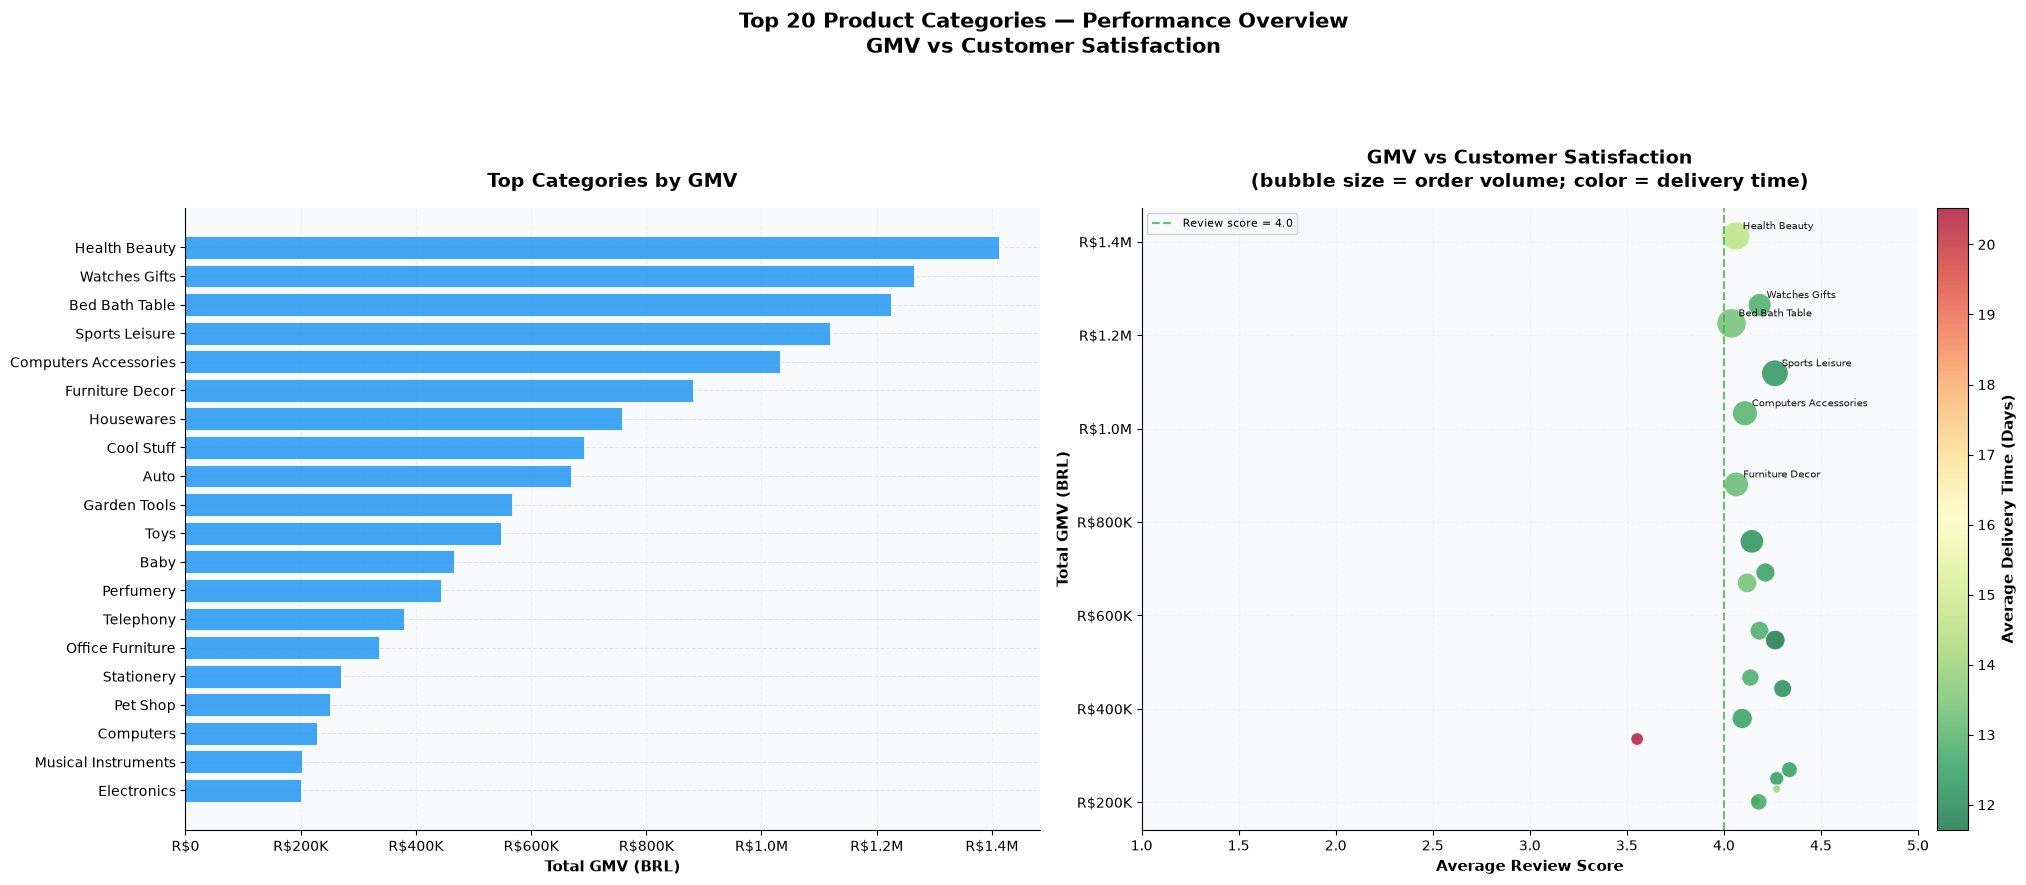

In [24]:

# 7.1 CATEGORY PERFORMANCE OVERVIEW
required_cols = [
    'product_category_name_english',
    'total_gmv',
    'avg_review_score',
    'total_orders',
    'avg_delivery_days'
]

missing_cols = [
    col for col in required_cols
    if col not in df_category.columns
]

if missing_cols:
    raise ValueError(
        f"Missing required columns: {missing_cols}"
    )

category_data = df_category.copy()

numeric_cols = [
    'total_gmv',
    'avg_review_score',
    'total_orders',
    'avg_delivery_days'
]

for col in numeric_cols:
    category_data[col] = pd.to_numeric(
        category_data[col], errors='coerce'
    )

if category_data['product_category_name_english'].duplicated().any():
    raise ValueError(
        "df_category must contain one row per product category. "
        "Check the aggregation query before plotting."
    )

# GMV is required for ranking and the bar chart
category_data = category_data.dropna(
    subset=[
        'product_category_name_english',
        'total_gmv'
    ]
)

# Exclude invalid negative GMV values
category_data = category_data[
    category_data['total_gmv'] >= 0
].copy()

if category_data.empty:
    raise ValueError(
        "No valid category data available for visualization."
    )

# Select Top 20 by GMV
top_cats = (
    category_data
    .nlargest(20, 'total_gmv')
    .copy()
)

# 2. HELPER: CONSISTENT BRL FORMAT
def format_brl(x, pos=None):
    if abs(x) >= 1e9:
        return f'R${x / 1e9:.1f}B'
    elif abs(x) >= 1e6:
        return f'R${x / 1e6:.1f}M'
    elif abs(x) >= 1e3:
        return f'R${x / 1e3:.0f}K'
    return f'R${x:.0f}'


# 3. CREATE FIGURE
fig, axes = plt.subplots(
    1, 2,
    figsize=(21, 9),
    gridspec_kw={'width_ratios': [1.05, 1.15]}
)

fig.suptitle(
    'Top 20 Product Categories — Performance Overview\n'
    'GMV vs Customer Satisfaction',
    fontsize=15,
    fontweight='bold'
)

# 4. PLOT 1: TOP CATEGORIES BY GMV
ax1 = axes[0]

top_cats_sorted = top_cats.sort_values(
    'total_gmv', ascending=True
)

category_labels = (
    top_cats_sorted['product_category_name_english']
    .str.replace('_', ' ', regex=False)
    .str.title()
)

ax1.barh(
    category_labels,
    top_cats_sorted['total_gmv'],
    color=COLORS['primary'],
    alpha=0.85,
    edgecolor='white',
    linewidth=0.7
)

ax1.set_xlabel('Total GMV (BRL)')
ax1.set_title(
    'Top Categories by GMV',
    fontweight='bold'
)

ax1.xaxis.set_major_formatter(
    mticker.FuncFormatter(format_brl)
)

ax1.grid(
    axis='x',
    linestyle='--',
    alpha=0.25
)
ax1.set_axisbelow(True)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# 5. PLOT 2: GMV VS REVIEW SCORE
ax2 = axes[1]

scatter_data = top_cats.dropna(
    subset=[
        'avg_review_score',
        'avg_delivery_days',
        'total_orders'
    ]
).copy()

scatter_data = scatter_data[
    scatter_data['avg_review_score'].between(1, 5)
    & (scatter_data['total_orders'] >= 0)
    & (scatter_data['avg_delivery_days'] >= 0)
].copy()

if not scatter_data.empty:

    # Normalize bubble area for easier visual comparison
    order_counts = scatter_data['total_orders'].to_numpy()

    if order_counts.max() > order_counts.min():
        bubble_sizes = np.interp(
            order_counts,
            (order_counts.min(), order_counts.max()),
            (35, 450)
        )
    else:
        bubble_sizes = np.full(
            len(scatter_data), 180.0
        )

    scatter = ax2.scatter(
        scatter_data['avg_review_score'],
        scatter_data['total_gmv'],
        s=bubble_sizes,
        c=scatter_data['avg_delivery_days'],
        cmap='RdYlGn_r',
        alpha=0.75,
        edgecolors='white',
        linewidth=0.8
    )

    cbar = fig.colorbar(
        scatter,
        ax=ax2,
        pad=0.02
    )
    cbar.set_label(
        'Average Delivery Time (Days)'
    )

    # Annotate up to 6 highest-GMV categories
    for _, row in scatter_data.nlargest(
        6, 'total_gmv'
    ).iterrows():

        label = (
            row['product_category_name_english']
            .replace('_', ' ')
            .title()
        )

        if len(label) > 22:
            label = label[:19] + '...'

        ax2.annotate(
            label,
            xy=(
                row['avg_review_score'],
                row['total_gmv']
            ),
            xytext=(5, 5),
            textcoords='offset points',
            fontsize=7,
            alpha=0.9
        )

else:
    ax2.text(
        0.5, 0.5,
        'No valid data for scatter plot',
        transform=ax2.transAxes,
        ha='center',
        va='center'
    )

# Satisfaction reference threshold
ax2.axvline(
    4.0,
    color=COLORS['success'],
    linestyle='--',
    linewidth=1.5,
    alpha=0.8,
    label='Review score = 4.0'
)

ax2.set_xlim(1, 5)
ax2.set_xticks(np.arange(1, 5.1, 0.5))

ax2.set_xlabel('Average Review Score')
ax2.set_ylabel('Total GMV (BRL)')
ax2.set_title(
    'GMV vs Customer Satisfaction\n'
    '(bubble size = order volume; color = delivery time)',
    fontweight='bold'
)

ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(format_brl)
)

ax2.grid(
    linestyle='--',
    alpha=0.2
)
ax2.set_axisbelow(True)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.legend(loc='best', fontsize=8)

# 6. LAYOUT AND EXPORT
fig.tight_layout(rect=[0, 0, 1, 0.92])

output_path = '../assets/eda/10_category_performance.png'
os.makedirs(
    os.path.dirname(output_path),
    exist_ok=True
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()


Health Beauty menjadi kategori dengan GMV tertinggi sekitar R$1,41 juta, diikuti Watches Gifts (R$1,26 juta) dan Bed Bath Table (R$1,22 juta). Mayoritas kategori dengan GMV tinggi memiliki rata-rata review score di atas 4,0 serta durasi pengiriman sekitar 12–15 hari. Namun, terdapat kategori dengan review score sekitar 3,55 dan durasi pengiriman sekitar 20 hari, yang menunjukkan potensi masalah pengalaman pelanggan.

Pertahankan performa kategori dengan kontribusi GMV terbesar dan prioritaskan evaluasi kategori yang memiliki kombinasi review score rendah serta durasi pengiriman panjang. Gunakan segmentasi berdasarkan GMV, volume pesanan, dan kepuasan pelanggan untuk mengoptimalkan strategi produk dan operasional.

In [25]:
query_customers = f"""
    SELECT
        customer_unique_id,
        rfm_segment,
        clv_tier,
        total_orders,
        total_clv,
        avg_order_value,
        recency_days,
        r_score, f_score, m_score,
        is_repeat_customer
    FROM `olist-ecommerce-analytics-1.olist_intermediate.int_customer_metrics`
"""
df_customers = run_query(client, query_customers)
print(f"dim_customers:          {len(df_customers):>8,} rows")

dim_customers:            96,096 rows


### 14. RFM Distribution

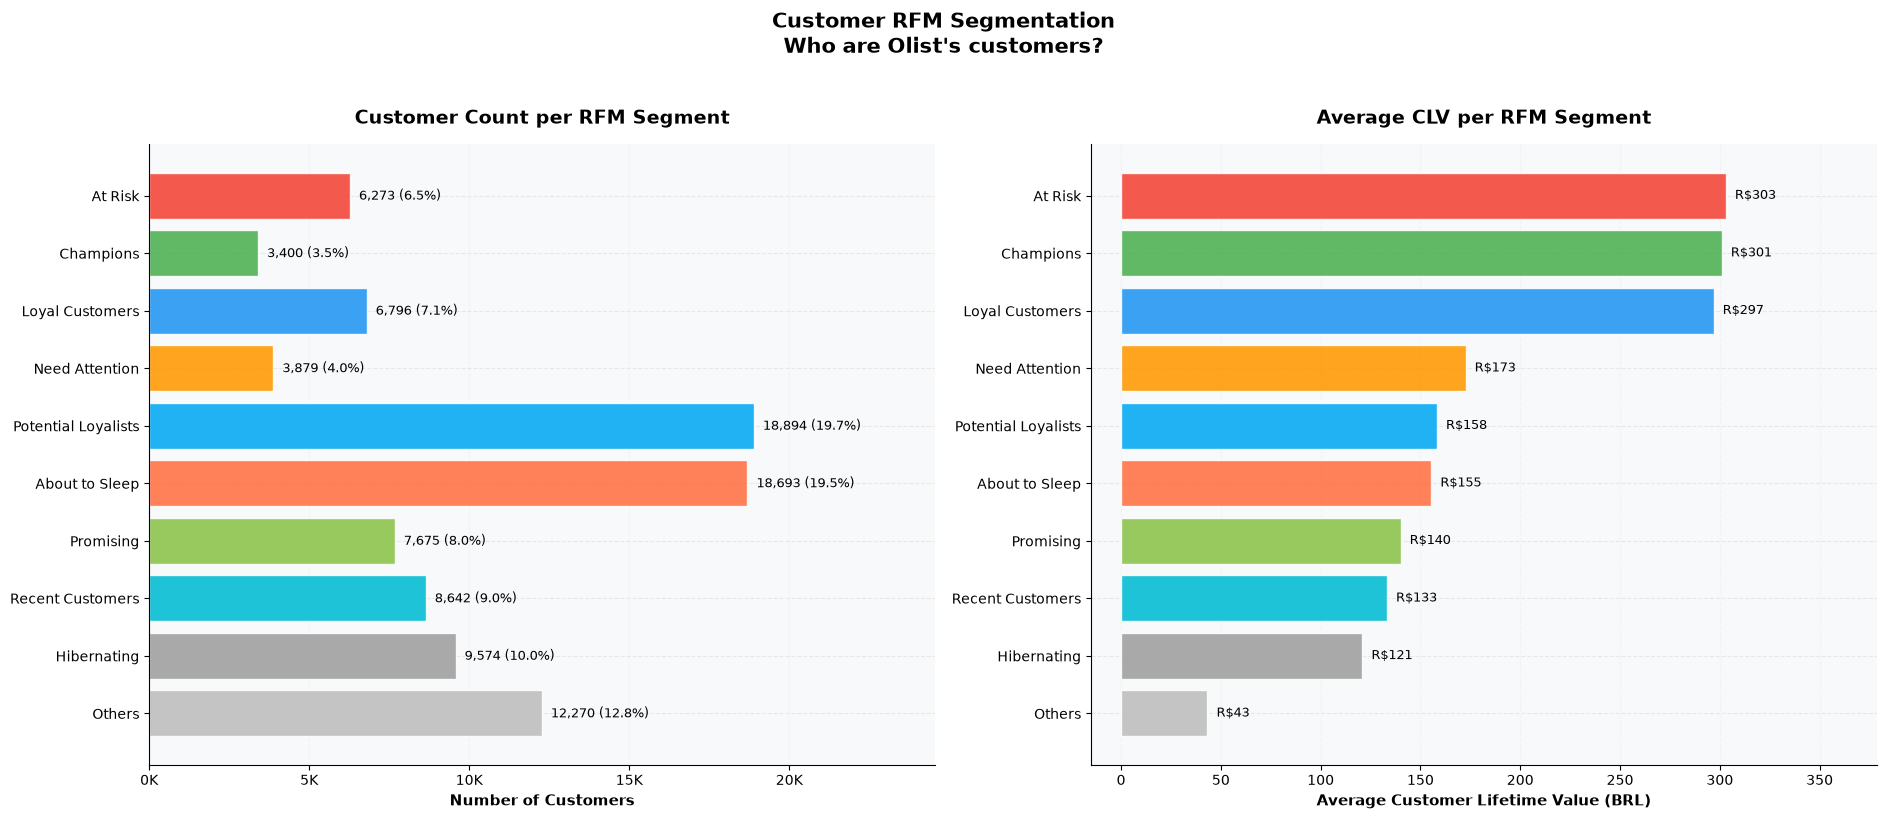


RFM SEGMENT SUMMARY
Segment                  Customers    Share       Avg CLV    Median CLV  Avg Orders  Avg Recency
----------------------------------------------------------------------------------------------------
At Risk                      6,273     6.5%         R$303         R$210         1.1        442.1
Champions                    3,400     3.5%         R$301         R$208         1.2         95.1
Loyal Customers              6,796     7.1%         R$297         R$206         1.2        226.6
Need Attention               3,879     4.0%         R$173         R$118         1.0        271.0
Potential Loyalists         18,894    19.7%         R$158         R$106         1.0        139.7
About to Sleep              18,693    19.5%         R$155         R$103         1.0        442.7
Promising                    7,675     8.0%         R$140          R$97         1.0        270.3
Recent Customers             8,642     9.0%         R$133          R$77         1.0        139.9
Hiber

In [26]:

# 7.2 RFM SEGMENT DISTRIBUTION

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

required_cols = [
    'customer_unique_id',
    'rfm_segment',
    'total_clv',
    'total_orders',
    'recency_days'
]

missing_cols = [
    col for col in required_cols
    if col not in df_customers.columns
]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

df_rfm = df_customers[required_cols].copy()

# Satu baris harus mewakili satu pelanggan
if df_rfm['customer_unique_id'].duplicated().any():
    raise ValueError(
        "df_customers contains duplicate customer_unique_id. "
        "Resolve the customer-level grain before aggregation."
    )

# Customer ID kosong tidak dapat dihitung sebagai pelanggan
df_rfm = df_rfm.dropna(subset=['customer_unique_id'])

# Tangani segmen yang kosong
df_rfm['rfm_segment'] = (
    df_rfm['rfm_segment']
    .fillna('Unclassified')
    .astype(str)
)

# Pastikan metrik numerik
numeric_cols = ['total_clv', 'total_orders', 'recency_days']

for col in numeric_cols:
    df_rfm[col] = pd.to_numeric(
        df_rfm[col], errors='coerce'
    )

if df_rfm.empty:
    raise ValueError("No valid customer records to visualize.")


# 2. AGGREGATE RFM SUMMARY
rfm_summary = (
    df_rfm.groupby('rfm_segment', as_index=False)
    .agg(
        customer_count=('customer_unique_id', 'nunique'),
        avg_clv=('total_clv', 'mean'),
        median_clv=('total_clv', 'median'),
        avg_orders=('total_orders', 'mean'),
        avg_recency=('recency_days', 'mean')
    )
    .sort_values(
        'avg_clv',
        ascending=False,
        na_position='last'
    )
    .reset_index(drop=True)
)

total_cust = rfm_summary['customer_count'].sum()

if total_cust == 0:
    raise ValueError("No customers available for plotting.")

rfm_summary['customer_pct'] = (
    rfm_summary['customer_count'] / total_cust * 100
)

rfm_colors = {
    'Champions':           '#4CAF50',
    'Loyal Customers':     '#2196F3',
    'Potential Loyalists': '#03A9F4',
    'Recent Customers':    '#00BCD4',
    'Promising':            '#8BC34A',
    'Need Attention':       '#FF9800',
    'About to Sleep':       '#FF7043',
    'At Risk':              '#F44336',
    'Hibernating':          '#9E9E9E',
    'Others':               '#BDBDBD',
    'Unclassified':         '#757575'
}

colors_rfm = [
    rfm_colors.get(seg, '#BDBDBD')
    for seg in rfm_summary['rfm_segment']
]

fig, axes = plt.subplots(1, 2, figsize=(19, 8))

fig.suptitle(
    "Customer RFM Segmentation\n"
    "Who are Olist's customers?",
    fontsize=15,
    fontweight='bold',
    y=1.02
)

# Plot 1: Customer count per segment
ax1 = axes[0]

bars1 = ax1.barh(
    rfm_summary['rfm_segment'],
    rfm_summary['customer_count'],
    color=colors_rfm,
    alpha=0.88,
    edgecolor='white',
    linewidth=1
)

max_count = rfm_summary['customer_count'].max()

ax1.set_xlim(0, max_count * 1.30 if max_count > 0 else 1)

for bar, (_, row) in zip(bars1, rfm_summary.iterrows()):
    count = row['customer_count']
    pct = row['customer_pct']

    ax1.text(
        count + max_count * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f'{count:,.0f} ({pct:.1f}%)',
        va='center',
        ha='left',
        fontsize=9
    )

ax1.set_xlabel('Number of Customers')
ax1.set_title('Customer Count per RFM Segment')
ax1.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x / 1e3:,.0f}K')
)
ax1.set_ylabel('')
ax1.grid(axis='x', linestyle='--', alpha=0.25)
ax1.set_axisbelow(True)
ax1.invert_yaxis()

# Plot 2: Average CLV per segment
ax2 = axes[1]

bars2 = ax2.barh(
    rfm_summary['rfm_segment'],
    rfm_summary['avg_clv'],
    color=colors_rfm,
    alpha=0.88,
    edgecolor='white',
    linewidth=1
)

valid_clv = rfm_summary['avg_clv'].dropna()

if not valid_clv.empty:
    clv_min = min(0, valid_clv.min())
    clv_max = max(0, valid_clv.max())
    clv_range = clv_max - clv_min

    if clv_range == 0:
        clv_range = max(abs(clv_max), 1)

    ax2.set_xlim(
        clv_min - clv_range * 0.05,
        clv_max + clv_range * 0.25
    )

    for bar, (_, row) in zip(bars2, rfm_summary.iterrows()):
        value = row['avg_clv']

        if pd.isna(value):
            continue

        offset = clv_range * 0.015
        label_x = value + offset if value >= 0 else value - offset
        alignment = 'left' if value >= 0 else 'right'

        ax2.text(
            label_x,
            bar.get_y() + bar.get_height() / 2,
            f'R${value:,.0f}',
            va='center',
            ha=alignment,
            fontsize=9
        )

ax2.set_xlabel('Average Customer Lifetime Value (BRL)')
ax2.set_title('Average CLV per RFM Segment')
ax2.set_ylabel('')
ax2.grid(axis='x', linestyle='--', alpha=0.25)
ax2.set_axisbelow(True)
ax2.invert_yaxis()

plt.tight_layout()

output_path = Path('../assets/eda/11_rfm_distribution.png')
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print('\nRFM SEGMENT SUMMARY')

print(
    f"{'Segment':<23} "
    f"{'Customers':>10} "
    f"{'Share':>8} "
    f"{'Avg CLV':>13} "
    f"{'Median CLV':>13} "
    f"{'Avg Orders':>11} "
    f"{'Avg Recency':>12}"
)

print('-' * 100)

for _, row in rfm_summary.iterrows():
    avg_clv = (
        f"R${row['avg_clv']:,.0f}"
        if pd.notna(row['avg_clv']) else 'N/A'
    )
    median_clv = (
        f"R${row['median_clv']:,.0f}"
        if pd.notna(row['median_clv']) else 'N/A'
    )
    avg_orders = (
        f"{row['avg_orders']:.1f}"
        if pd.notna(row['avg_orders']) else 'N/A'
    )
    avg_recency = (
        f"{row['avg_recency']:.1f}"
        if pd.notna(row['avg_recency']) else 'N/A'
    )

    print(
        f"{row['rfm_segment']:<23} "
        f"{row['customer_count']:>10,.0f} "
        f"{row['customer_pct']:>7.1f}% "
        f"{avg_clv:>13} "
        f"{median_clv:>13} "
        f"{avg_orders:>11} "
        f"{avg_recency:>12}"
    )

print(f'Total customers: {total_cust:,}')


Segmentasi RFM menunjukkan bahwa pelanggan Olist didominasi oleh Potential Loyalists (19,7%) dan About to Sleep (19,5%). Sementara itu, Champions dan Loyal Customers hanya mencakup 10,6% dari total pelanggan, tetapi memiliki Average CLV yang relatif tinggi. Segmen At Risk bahkan mencatat Average CLV tertinggi sebesar R$303, menunjukkan adanya kelompok pelanggan bernilai tinggi yang berpotensi tidak kembali melakukan pembelian.

Prioritaskan strategi retensi untuk pelanggan At Risk, dorong Potential Loyalists menjadi pelanggan loyal, dan lakukan kampanye reaktivasi pada pelanggan About to Sleep. Terapkan strategi pemasaran yang dipersonalisasi berdasarkan nilai dan perilaku pelanggan untuk meningkatkan loyalitas serta nilai pelanggan dalam jangka panjang.

In [27]:

# 0. VALIDATE DATA GRAIN

# Monthly data: ideally one row per month
if 'year_month' in df_monthly.columns:
    if df_monthly['year_month'].duplicated().any():
        raise ValueError(
            "df_monthly memiliki lebih dari satu baris per bulan. "
            "Agregasikan menjadi satu baris per bulan sebelum "
            "menjumlahkan total_gmv."
        )

# Delivered orders: ideally one row per order
if 'order_id' in df_delivered.columns:
    if df_delivered['order_id'].duplicated().any():
        raise ValueError(
            "df_delivered memiliki order_id duplikat. "
            "Pastikan data berada pada grain satu baris per order."
        )

# Customers: ideally one row per unique customer
if 'customer_unique_id' in df_customers.columns:
    if df_customers['customer_unique_id'].duplicated().any():
        raise ValueError(
            "df_customers memiliki customer_unique_id duplikat. "
            "Pastikan grain satu baris per pelanggan unik."
        )

# 1. REVENUE & GMV

monthly_gmv = pd.to_numeric(
    df_monthly['total_gmv'], errors='coerce'
)

total_gmv = monthly_gmv.sum(min_count=1)

order_gmv = pd.to_numeric(
    df_delivered['total_gmv'], errors='coerce'
).dropna()

print("\n1. REVENUE & GMV")
print(
    f"   Total GMV: R${total_gmv:,.2f}"
    if pd.notna(total_gmv)
    else "   Total GMV: N/A"
)
print(f"   Orders used for AOV: {len(order_gmv):,}")

if not order_gmv.empty:
    print(f"   Mean AOV:       R${order_gmv.mean():,.2f}")
    print(f"   Median AOV:     R${order_gmv.median():,.2f}")
    print(f"   GMV skewness:   {order_gmv.skew():.2f}")
else:
    print("   Mean AOV:       N/A")
    print("   Median AOV:     N/A")
    print("   GMV skewness:   N/A")

# 2. DELIVERY PERFORMANCE
duration = pd.to_numeric(
    df_delivered['purchase_to_delivery_days'],
    errors='coerce'
)

not_anomaly = df_delivered[
    'is_order_date_anomaly'
].eq(False)

valid_duration = (
    duration.notna()
    & np.isfinite(duration)
    & duration.ge(0)
    & not_anomaly
)

del_clean = df_delivered.loc[valid_duration].copy()
del_clean['_delivery_days'] = duration.loc[valid_duration]

on_time_flag = df_delivered['is_ontime_delivery']

valid_otdr = not_anomaly & on_time_flag.notna()
otdr_denom = int(valid_otdr.sum())

otdr = int(
    (
        df_delivered.loc[valid_otdr, 'is_ontime_delivery']
        .eq(True)
    ).sum()
)

print("\n2. DELIVERY PERFORMANCE")

if otdr_denom > 0:
    print(f"   OTDR:            {otdr / otdr_denom * 100:.1f}%")
    print(f"   Eligible orders: {otdr_denom:,}")
else:
    print("   OTDR:            N/A (no valid observations)")

if not del_clean.empty:
    print(
        f"   Avg delivery:    "
        f"{del_clean['_delivery_days'].mean():.1f} days"
    )
    print(
        f"   Median delivery: "
        f"{del_clean['_delivery_days'].median():.1f} days"
    )
else:
    print("   Avg delivery:    N/A")
    print("   Median delivery: N/A")


# 3. CUSTOMER SATISFACTION
reviews = pd.to_numeric(
    df_delivered['review_score'], errors='coerce'
).dropna()

reviews = reviews[reviews.between(1, 5)]

print("\n3. CUSTOMER SATISFACTION")

if not reviews.empty:
    print(f"   Valid reviews:      {len(reviews):,}")
    print(f"   Avg review score:   {reviews.mean():.3f}")
    print(f"   Positive rate (4–5): {(reviews >= 4).mean() * 100:.1f}%")
    print(f"   Negative rate (1–2): {(reviews <= 2).mean() * 100:.1f}%")
else:
    print("   No valid review scores available.")


# 4. CUSTOMER BEHAVIOR
repeat = df_customers['is_repeat_customer'].dropna()

print("\n4. CUSTOMER BEHAVIOR")
print(f"   Unique customers: {len(df_customers):,}")

if not repeat.empty:
    repeat_rate = repeat.astype(bool).mean() * 100
    print(f"   Repeat purchase rate: {repeat_rate:.1f}%")
    print(f"   Customers with known repeat status: {len(repeat):,}")
else:
    print("   Repeat purchase rate: N/A")


# 5. PRODUCT PERFORMANCE
category_gmv = df_category[
    ['product_category_name_english', 'total_gmv']
].copy()

category_gmv['total_gmv'] = pd.to_numeric(
    category_gmv['total_gmv'], errors='coerce'
)

category_gmv = category_gmv.dropna(
    subset=['product_category_name_english', 'total_gmv']
)

if category_gmv['product_category_name_english'].duplicated().any():
    raise ValueError(
        "df_category memiliki kategori duplikat. "
        "Agregasikan GMV per kategori sebelum mencari top category."
    )

print("\n5. PRODUCT PERFORMANCE")

if not category_gmv.empty:
    top_cat = category_gmv.loc[category_gmv['total_gmv'].idxmax()]

    print(
        f"   Top category by GMV: "
        f"{top_cat['product_category_name_english']}"
    )
    print(f"   Top category GMV:    R${top_cat['total_gmv']:,.2f}")
    print(f"   Total categories:     {len(category_gmv):,}")
else:
    print("   No valid category data available.")


1. REVENUE & GMV
   Total GMV: R$15,212,037.88
   Orders used for AOV: 96,478
   Mean AOV:       R$159.83
   Median AOV:     R$105.28
   GMV skewness:   9.37

2. DELIVERY PERFORMANCE
   OTDR:            91.8%
   Eligible orders: 95,097
   Avg delivery:    12.6 days
   Median delivery: 10.0 days

3. CUSTOMER SATISFACTION
   Valid reviews:      95,832
   Avg review score:   4.156
   Positive rate (4–5): 78.9%
   Negative rate (1–2): 12.8%

4. CUSTOMER BEHAVIOR
   Unique customers: 96,096
   Repeat purchase rate: 2.9%
   Customers with known repeat status: 96,096

5. PRODUCT PERFORMANCE
   Top category by GMV: health_beauty
   Top category GMV:    R$1,412,089.53
   Total categories:     71
